In [1]:
!pip install -q geemap rasterio

import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import os
import shutil

from pathlib import Path
from google.colab import drive

# Mount Google Drive so the patches are not lost when Colab closes
drive.mount("/content/drive")

# Replace this with the Google Earth Engine project ID used in your labs
PROJECT_ID = "geog761-lrei069"

ee.Authenticate()
ee.Initialize(project=PROJECT_ID)

print("Earth Engine connected successfully.")

Mounted at /content/drive
Earth Engine connected successfully.


In [2]:
import requests
import pandas as pd
from pathlib import Path

# ArcGIS World Port Index point layer
query_url = (
    "https://services-eu1.arcgis.com/BuS9rtTsYEV5C0xh/"
    "arcgis/rest/services/World_Port_Index/FeatureServer/0/query"
)

all_records = []
offset = 0
page_size = 2000

while True:
    parameters = {
        "where": "1=1",
        "outFields": (
            "OBJECTID,INDEX_NO,PORT_NAME,COUNTRY,"
            "LATITUDE,LONGITUDE"
        ),
        "returnGeometry": "false",
        "resultOffset": offset,
        "resultRecordCount": page_size,
        "orderByFields": "OBJECTID",
        "f": "json"
    }

    response = requests.get(
        query_url,
        params=parameters,
        timeout=120
    )
    response.raise_for_status()

    result = response.json()

    if "error" in result:
        raise RuntimeError(result["error"])

    records = [
        feature["attributes"]
        for feature in result.get("features", [])
    ]

    all_records.extend(records)

    if len(records) < page_size:
        break

    offset += page_size

world_ports = pd.DataFrame(all_records)

print("All World Port Index ports:", len(world_ports))
display(world_ports.head())

All World Port Index ports: 3630


,OBJECTID,INDEX_NO,PORT_NAME,COUNTRY,LATITUDE,LONGITUDE
0,1,61090,SHAKOTAN,RU,43.866667,146.833333
1,2,61110,MOMBETSU KO,JP,44.350000,143.350000
2,3,5750,CHARLOTTETOWN,CA,46.233333,-63.133333
3,4,61120,ABASHIRI KO,JP,44.016667,144.283333
4,5,61130,NEMURO KO,JP,43.333333,145.583333


In [3]:
# Filter the World Port Index to Pacific Island ports and save as CSV

from pathlib import Path

pacific_country_values = {
    # Two-letter country codes
    "AS",  # American Samoa
    "CK",  # Cook Islands
    "FJ",  # Fiji
    "PF",  # French Polynesia
    "GU",  # Guam
    "KI",  # Kiribati
    "MH",  # Marshall Islands
    "FM",  # Federated States of Micronesia
    "NR",  # Nauru
    "NC",  # New Caledonia
    "NU",  # Niue
    "MP",  # Northern Mariana Islands
    "PW",  # Palau
    "PG",  # Papua New Guinea
    "WS",  # Samoa
    "SB",  # Solomon Islands
    "TK",  # Tokelau
    "TO",  # Tonga
    "TV",  # Tuvalu
    "VU",  # Vanuatu
    "WF",  # Wallis and Futuna

    # Full country names
    "AMERICAN SAMOA",
    "COOK ISLANDS",
    "FIJI",
    "FRENCH POLYNESIA",
    "GUAM",
    "KIRIBATI",
    "MARSHALL ISLANDS",
    "MICRONESIA, FEDERATED STATES OF",
    "FEDERATED STATES OF MICRONESIA",
    "NAURU",
    "NEW CALEDONIA",
    "NIUE",
    "NORTHERN MARIANA ISLANDS",
    "PALAU",
    "PAPUA NEW GUINEA",
    "SAMOA",
    "SOLOMON ISLANDS",
    "TOKELAU",
    "TONGA",
    "TUVALU",
    "VANUATU",
    "WALLIS AND FUTUNA"
}

# Standardise the country field
world_ports["COUNTRY_FILTER"] = (
    world_ports["COUNTRY"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Select Pacific Island ports
pacific_ports = (
    world_ports[
        world_ports["COUNTRY_FILTER"].isin(
            pacific_country_values
        )
    ]
    .drop(columns="COUNTRY_FILTER")
    .dropna(subset=["LATITUDE", "LONGITUDE"])
    .drop_duplicates(
        subset=["PORT_NAME", "LATITUDE", "LONGITUDE"]
    )
    .reset_index(drop=True)
)

# Create the Google Drive output folder
output_folder = Path(
    "/content/drive/MyDrive/GEOG761_port_training"
)

output_folder.mkdir(
    parents=True,
    exist_ok=True
)

# Save the complete and Pacific-only datasets
world_ports.drop(
    columns="COUNTRY_FILTER",
    errors="ignore"
).to_csv(
    output_folder / "world_port_index_all.csv",
    index=False
)

pacific_ports.to_csv(
    output_folder / "pacific_ports.csv",
    index=False
)

print("All World Port Index ports:", len(world_ports))
print("Pacific ports found:", len(pacific_ports))
print("Saved to:", output_folder / "pacific_ports.csv")

display(pacific_ports.head(20))

All World Port Index ports: 3630
Pacific ports found: 70
Saved to: /content/drive/MyDrive/GEOG761_port_training/pacific_ports.csv


,OBJECTID,INDEX_NO,PORT_NAME,COUNTRY,LATITUDE,LONGITUDE
0,952,57100,TULAGHI,SB,-9.100000,160.150000
1,953,57120,HONIARA,SB,-9.416667,159.950000
2,954,57200,LUGANVILLE,VU,-15.516667,167.166667
3,955,57230,PORT VILA,VU,-17.733333,168.316667
4,956,57245,FORARI BAY,VU,-17.683333,168.550000
5,957,57275,BAIE DE KOUAOUA,NC,-21.383333,165.816667
6,1120,57070,YANDINA,SB,-9.083333,159.216667
7,1222,56400,MAJURO ATOLL,MH,7.083333,171.383333
8,1223,56450,TARAWA ATOLL,KI,1.333333,172.933333
9,1224,56500,NAURU,NR,-0.533333,166.916667


## Storm-track port selection (pilot)

Instead of hand-picking ports and dates, these cells use the IBTrACS cyclone tracks to find
Pacific ports that a storm actually hit since 2015, then pick the 10 best-hit ports for a pilot.
The output is the same `ports` table the original patch code below already uses.

Cells A–C load the tracks and measure how close every storm came to every port.
Cell E builds all candidate samples (storm hits plus "no storm" controls).
The pilot cell picks the 10 ports, and the last cell is a quick coordinate check.

In [4]:
# Cell A — settings and IBTrACS download

import re
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

IBTRACS_BASE_URL = (
    "https://www.ncei.noaa.gov/data/"
    "international-best-track-archive-for-climate-stewardship-ibtracs/"
    "v04r01/access/csv/"
)

# South Pacific covers Vanuatu, Fiji, Samoa, Tonga etc.; West Pacific covers
# Guam, Palau, FSM, Marshall Islands and Northern Marianas.
IBTRACS_FILES = [
    "ibtracs.SP.list.v04r01.csv",
    "ibtracs.WP.list.v04r01.csv",
]

IBTRACS_DIR = Path("/content/drive/MyDrive/GEOG761_port_training/ibtracs")
STORM_OUTPUT_DIR = Path("/content/drive/MyDrive/GEOG761_port_training")

# Sentinel-1 routine acquisitions start in late 2014.
SENTINEL1_START = pd.Timestamp("2015-01-01")

# Exposure rules
SEARCH_RADIUS_KM = 1500   # keep port–storm pairs up to this distance (needed for spatial controls)
NEAR_MISS_KM = 300        # closer than this but outside the gale radius = "near_miss"
QUIET_RADIUS_KM = 500     # a control window must have no storm closer than this
DEFAULT_R34_KM = 150      # used only when IBTrACS has no 34 kt wind radius
DEFAULT_R64_KM = 50       # used only when IBTrACS has no 64 kt wind radius
EVENT_CLASSES = ["hurricane_force", "gale_force"]

# Image windows around the time of closest approach (t0)
PRE_DAYS = 10            # pre window: t0 - 60 d  ...  t0 - 2 d
PRE_GAP_DAYS = 2
POST_GAP_DAYS = 1         # post window: t0 + 1 d  ...  t0 + 46 d
POST_DAYS = 10

# Controls
CONTROL_YEAR_SHIFTS = [-1, 1, -2, 2, -3, 3]
TEMPORAL_CONTROLS_PER_EVENT = 1
SPATIAL_CONTROLS_PER_STORM = 3
RANDOM_SEED = 761

# The post window must already be over (with a margin) for imagery to exist.
LATEST_EVENT_DATE = (
    pd.Timestamp.today().normalize()
    - pd.Timedelta(days=POST_GAP_DAYS + POST_DAYS + 7)
)

NM_TO_KM = 1.852
QUADRANTS = ["NE", "SE", "SW", "NW"]


def download_ibtracs(file_names=IBTRACS_FILES, folder=IBTRACS_DIR):
    """Download the IBTrACS basin CSVs once (cached on Drive) and load them."""

    folder.mkdir(parents=True, exist_ok=True)
    frames = []

    for name in file_names:
        path = folder / name

        if not path.exists():
            print("Downloading", name)
            with requests.get(IBTRACS_BASE_URL + name, stream=True, timeout=600) as response:
                response.raise_for_status()
                with open(path, "wb") as file:
                    for chunk in response.iter_content(chunk_size=1 << 20):
                        file.write(chunk)

        # The second line of each IBTrACS CSV holds units, and blanks are " ".
        frames.append(
            pd.read_csv(path, skiprows=[1], na_values=[" "], low_memory=False)
        )

    return pd.concat(frames, ignore_index=True)


raw_tracks = download_ibtracs()
print("IBTrACS rows loaded:", len(raw_tracks))

IBTrACS rows loaded: 326393


In [5]:
# Cell B — clean the tracks and interpolate them to 30-minute steps

def max_radius_km(tracks, threshold):
    """Largest of the four quadrant wind radii (nautical miles -> km)."""

    columns = [f"USA_R{threshold}_{q}" for q in QUADRANTS if f"USA_R{threshold}_{q}" in tracks]
    if not columns:
        return pd.Series(np.nan, index=tracks.index)

    radii = tracks[columns].apply(pd.to_numeric, errors="coerce")
    return radii.max(axis=1, skipna=True) * NM_TO_KM


def prepare_tracks(raw):
    """Keep main tracks in the Sentinel-1 era with numeric position, wind and radii."""

    tracks = raw.copy()
    tracks["ISO_TIME"] = pd.to_datetime(tracks["ISO_TIME"], errors="coerce")

    # Spur tracks are alternative positions of the same storm; keep the main track.
    if "TRACK_TYPE" in tracks:
        tracks = tracks[~tracks["TRACK_TYPE"].astype(str).str.lower().str.startswith("spur")]

    for column in ["LAT", "LON", "USA_WIND", "WMO_WIND"]:
        if column in tracks:
            tracks[column] = pd.to_numeric(tracks[column], errors="coerce")

    # JTWC 1-minute winds (USA_WIND) cover both basins consistently; fall back to WMO.
    wind = tracks["USA_WIND"] if "USA_WIND" in tracks else pd.Series(np.nan, index=tracks.index)
    if "WMO_WIND" in tracks:
        wind = wind.fillna(tracks["WMO_WIND"])
    tracks["wind_kt"] = wind

    tracks["r34_km"] = max_radius_km(tracks, 34)
    tracks["r64_km"] = max_radius_km(tracks, 64)

    tracks = tracks.dropna(subset=["ISO_TIME", "LAT", "LON"])
    tracks = tracks[tracks["ISO_TIME"] >= SENTINEL1_START - pd.Timedelta(days=PRE_DAYS)]
    tracks = tracks.drop_duplicates(subset=["SID", "ISO_TIME"])

    keep = ["SID", "SEASON", "NAME", "ISO_TIME", "LAT", "LON", "wind_kt", "r34_km", "r64_km"]
    return tracks[keep].sort_values(["SID", "ISO_TIME"]).reset_index(drop=True)


def interpolate_storm(storm, step="30min"):
    """Interpolate one storm's 3-hourly fixes so the closest approach is not missed.

    Longitudes are unwrapped first so storms crossing the dateline interpolate
    through 180° instead of jumping across the globe.
    """

    storm = storm.drop_duplicates("ISO_TIME").set_index("ISO_TIME").sort_index()

    numeric = storm[["LAT", "LON", "wind_kt", "r34_km", "r64_km"]].astype(float).copy()
    numeric["LON"] = np.degrees(np.unwrap(np.radians(numeric["LON"].to_numpy())))

    new_times = pd.date_range(numeric.index.min(), numeric.index.max(), freq=step)
    combined = numeric.reindex(numeric.index.union(new_times))
    combined = combined.interpolate(method="time", limit_area="inside")
    result = combined.loc[new_times]

    result["LON"] = ((result["LON"] + 180) % 360) - 180
    result["SID"] = storm["SID"].iloc[0]
    return result.rename_axis("ISO_TIME").reset_index()


tracks = prepare_tracks(raw_tracks)

storm_info = (
    tracks.groupby("SID")
    .agg(
        storm_name=("NAME", "first"),
        season=("SEASON", "first"),
        lifetime_max_wind_kt=("wind_kt", "max"),
    )
    .reset_index()
)

track_points = pd.concat(
    [interpolate_storm(storm) for _, storm in tracks.groupby("SID")],
    ignore_index=True,
)

print("Storms in the Sentinel-1 era:", tracks["SID"].nunique())
print("Interpolated track points:", len(track_points))

Storms in the Sentinel-1 era: 498
Interpolated track points: 187130


In [6]:
# Cell C — closest approach of every storm to every Pacific port

def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance; handles the dateline correctly."""

    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    )
    return 2 * 6371.0088 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def slugify(text):
    return re.sub(r"[^a-z0-9]+", "_", str(text).lower()).strip("_")


def build_port_table(pacific_ports):
    """Pacific WPI ports with clean names and a unique key.

    World Port Index points are accurate enough for storm selection: a 1–3 km
    offset doesn't change whether a port was inside a storm's wind field.
    Wharf coordinates are checked later, only for the ports that get selected.
    """

    table = pacific_ports.copy()
    table["PORT_NAME"] = table["PORT_NAME"].astype(str).str.strip().str.upper()
    table["COUNTRY"] = table["COUNTRY"].astype(str).str.strip().str.upper()
    table["latitude"] = table["LATITUDE"].astype(float)
    table["longitude"] = table["LONGITUDE"].astype(float)
    table["coordinate_status"] = "wpi"
    table["port_key"] = [
        f"{slugify(name)}_{slugify(country)}"
        for name, country in zip(table["PORT_NAME"], table["COUNTRY"])
    ]
    return table.drop_duplicates("port_key").reset_index(drop=True)


def closest_approaches(port_table, track_points, search_radius_km=SEARCH_RADIUS_KM):
    """One row per port–storm pair: distance, time and storm state at closest approach."""

    lat = track_points["LAT"].to_numpy()
    lon = track_points["LON"].to_numpy()
    sid = track_points["SID"].to_numpy()
    records = []

    for _, port in port_table.iterrows():
        distance = haversine_km(port["latitude"], port["longitude"], lat, lon)
        nearby = pd.DataFrame({"SID": sid, "distance_km": distance})
        nearby = nearby[nearby["distance_km"] <= search_radius_km]
        if nearby.empty:
            continue

        best_rows = nearby.groupby("SID")["distance_km"].idxmin().to_numpy()
        points = track_points.loc[best_rows]

        records.append(pd.DataFrame({
            "port_key": port["port_key"],
            "port_name": port["PORT_NAME"],
            "country": port["COUNTRY"],
            "world_port_index": port["INDEX_NO"],
            "latitude": port["latitude"],
            "longitude": port["longitude"],
            "coordinate_status": port["coordinate_status"],
            "storm_sid": points["SID"].to_numpy(),
            "distance_km": distance[best_rows],
            "cpa_time": points["ISO_TIME"].to_numpy(),
            "wind_kt_at_cpa": points["wind_kt"].to_numpy(),
            "r34_km": points["r34_km"].to_numpy(),
            "r64_km": points["r64_km"].to_numpy(),
        }))

    approaches = pd.concat(records, ignore_index=True)
    approaches = approaches.merge(storm_info, left_on="storm_sid", right_on="SID", how="left")
    return approaches.drop(columns="SID")


def classify_exposure(approaches):
    """Hurricane-force / gale-force if the port lies inside the 64 kt / 34 kt wind radius."""

    df = approaches.copy()
    wind = df["wind_kt_at_cpa"].fillna(0)

    # A missing or zero radius on a storm strong enough to have one -> use the default.
    r64 = df["r64_km"].where(df["r64_km"] > 0)
    r34 = df["r34_km"].where(df["r34_km"] > 0)
    df["radius_source"] = np.where(r34.notna(), "ibtracs", "default")
    r64 = r64.fillna(pd.Series(np.where(wind >= 64, DEFAULT_R64_KM, 0.0), index=df.index))
    r34 = r34.fillna(pd.Series(np.where(wind >= 34, DEFAULT_R34_KM, 0.0), index=df.index))

    conditions = [
        (wind >= 64) & (df["distance_km"] <= r64),
        (wind >= 34) & (df["distance_km"] <= r34),
        df["distance_km"] <= NEAR_MISS_KM,
    ]
    df["exposure_class"] = np.select(
        conditions, ["hurricane_force", "gale_force", "near_miss"], default="distant"
    )
    return df


port_table = build_port_table(pacific_ports)
approaches = classify_exposure(closest_approaches(port_table, track_points))
approaches = approaches.sort_values(["port_key", "cpa_time"]).reset_index(drop=True)

approaches.to_csv(STORM_OUTPUT_DIR / "storm_port_approaches.csv", index=False)

print("Port–storm pairs within", SEARCH_RADIUS_KM, "km:", len(approaches))
display(approaches["exposure_class"].value_counts())

Port–storm pairs within 1500 km: 5307


,count
exposure_class,
distant,4592
near_miss,447
gale_force,233
hurricane_force,35


In [7]:
# Cell E — build event samples, temporal controls and spatial controls

COMPOUND_GAP_DAYS = 14   # storms hitting the same port within 14 days form one compound event
SEVERITY_RANK = {"hurricane_force": 2, "gale_force": 1}


def add_windows(df, pre_anchor, post_anchor=None, shift_years=0):
    """Pre window ends before pre_anchor; post window starts after post_anchor."""

    pre_t0 = pd.to_datetime(pd.Series(list(pre_anchor), index=df.index)).dt.normalize()
    post_t0 = pre_t0 if post_anchor is None else (
        pd.to_datetime(pd.Series(list(post_anchor), index=df.index)).dt.normalize()
    )
    if shift_years:
        pre_t0 = pre_t0 + pd.DateOffset(years=shift_years)
        post_t0 = post_t0 + pd.DateOffset(years=shift_years)

    out = df.copy()
    out["anchor_date"] = post_t0
    out["pre_start"] = (pre_t0 - pd.Timedelta(days=PRE_DAYS)).dt.strftime("%Y-%m-%d")
    out["pre_end"] = (pre_t0 - pd.Timedelta(days=PRE_GAP_DAYS)).dt.strftime("%Y-%m-%d")
    out["post_start"] = (post_t0 + pd.Timedelta(days=POST_GAP_DAYS)).dt.strftime("%Y-%m-%d")
    out["post_end"] = (
        post_t0 + pd.Timedelta(days=POST_GAP_DAYS + POST_DAYS)
    ).dt.strftime("%Y-%m-%d")
    return out


def storms_in_window(port_key, start, end, radius_km, exclude_sids=(), min_wind_kt=34):
    """Gale-strength (or stronger) storms passing this port within radius_km during [start, end]."""

    cpa = pd.to_datetime(approaches["cpa_time"])
    rows = approaches[
        (approaches["port_key"] == port_key)
        & (approaches["distance_km"] <= radius_km)
        & (approaches["wind_kt_at_cpa"].fillna(0) >= min_wind_kt)
        & (cpa >= pd.Timestamp(start))
        & (cpa <= pd.Timestamp(end))
    ]
    return rows[~rows["storm_sid"].isin(list(exclude_sids))]


def window_is_usable(row):
    return (
        pd.Timestamp(row["pre_start"]) >= SENTINEL1_START
        and pd.Timestamp(row["anchor_date"]) <= LATEST_EVENT_DATE
    )


def merge_compound_events(exposed):
    """Combine storms that hit the same port within COMPOUND_GAP_DAYS (e.g. Judy + Kevin)."""

    merged = []
    for _, port_rows in exposed.sort_values("cpa_time").groupby("port_key"):
        clusters, current, last_time = [], [], None
        for _, row in port_rows.iterrows():
            t = pd.Timestamp(row["cpa_time"])
            if current and (t - last_time).days > COMPOUND_GAP_DAYS:
                clusters.append(current)
                current = []
            current.append(row)
            last_time = t
        if current:
            clusters.append(current)

        for cluster in clusters:
            c = pd.DataFrame(cluster)
            c["_rank"] = c["exposure_class"].map(SEVERITY_RANK)
            worst = c.sort_values(["_rank", "distance_km"], ascending=[False, True]).iloc[0].copy()
            worst["storm_sids"] = list(c["storm_sid"])
            worst["storm_sid"] = ";".join(c["storm_sid"])
            worst["storm_name"] = "/".join(c["storm_name"].astype(str).str.title())
            worst["first_cpa"] = pd.to_datetime(c["cpa_time"]).min()
            worst["last_cpa"] = pd.to_datetime(c["cpa_time"]).max()
            merged.append(worst.drop(labels="_rank"))

    return pd.DataFrame(merged).reset_index(drop=True)


SAMPLE_COLUMNS = [
    "sample_id", "sample_type", "port_key", "port_name", "country", "world_port_index",
    "latitude", "longitude", "coordinate_status",
    "disaster", "storm_sid", "storm_name", "season",
    "cpa_time", "distance_km", "wind_kt_at_cpa", "r34_km", "r64_km",
    "radius_source", "exposure_class", "control_for",
    "pre_start", "pre_end", "post_start", "post_end", "label",
]
STORM_COLUMNS = ["storm_sid", "storm_name", "cpa_time", "distance_km",
                 "wind_kt_at_cpa", "r34_km", "r64_km", "radius_source"]

# ---- Events --------------------------------------------------------------
exposed = approaches[approaches["exposure_class"].isin(EVENT_CLASSES)]
events = merge_compound_events(exposed)
events = add_windows(events, events["first_cpa"], events["last_cpa"])
events = events[events.apply(window_is_usable, axis=1)]

# Drop events whose windows contain another gale-strength storm passing close by.
events["other_storm_in_window"] = [
    not storms_in_window(r.port_key, r.pre_start, r.post_end, NEAR_MISS_KM, r.storm_sids).empty
    for r in events.itertuples()
]
contaminated = events[events["other_storm_in_window"]]
events = events[~events["other_storm_in_window"]].copy()

events["sample_type"] = "event"
events["control_for"] = ""
events["disaster"] = [
    f"Tropical Cyclone {name} ({season})"
    for name, season in zip(events["storm_name"], events["season"])
]
events["sample_id"] = [
    f"{key}_{slugify(name)}_{season}"
    for key, name, season in zip(events["port_key"], events["storm_name"], events["season"])
]

# ---- Temporal controls: same port, same season, a quiet year ----------------
temporal_rows = []
for _, event in events.iterrows():
    found = 0
    for shift in CONTROL_YEAR_SHIFTS:
        control = add_windows(
            event.to_frame().T, [event["first_cpa"]], [event["last_cpa"]], shift_years=shift
        ).iloc[0].copy()
        if not window_is_usable(control):
            continue
        if not storms_in_window(control["port_key"], control["pre_start"],
                                control["post_end"], QUIET_RADIUS_KM).empty:
            continue

        control["sample_type"] = "control_temporal"
        control["control_for"] = event["sample_id"]
        control["exposure_class"] = "none"
        control["disaster"] = "No cyclone (temporal control)"
        control[STORM_COLUMNS] = np.nan
        control["season"] = pd.Timestamp(control["anchor_date"]).year
        control["sample_id"] = (
            f"{control['port_key']}_ctrl_{pd.Timestamp(control['anchor_date']):%Y%m%d}"
        )
        temporal_rows.append(control)

        found += 1
        if found >= TEMPORAL_CONTROLS_PER_EVENT:
            break

temporal_controls = pd.DataFrame(temporal_rows)

# ---- Spatial controls: regional ports the same storm(s) missed, same dates ---
rng = np.random.default_rng(RANDOM_SEED)
spatial_rows = []

for storm_key, storm_events in events.groupby("storm_sid"):
    sids = storm_key.split(";")
    exposed_ports = set(storm_events["port_key"])

    # Closest distance of each regional port to any of these storms.
    pairs = approaches[approaches["storm_sid"].isin(sids)]
    nearest = pairs.groupby("port_key")["distance_km"].min()
    candidate_keys = nearest[(nearest > QUIET_RADIUS_KM) & ~nearest.index.isin(exposed_ports)].index

    candidates = (
        pairs[pairs["port_key"].isin(candidate_keys)]
        .sort_values("distance_km")
        .drop_duplicates("port_key")
        .copy()
    )
    if candidates.empty:
        continue

    n = len(candidates)
    candidates = add_windows(
        candidates,
        [storm_events["first_cpa"].min()] * n,
        [storm_events["last_cpa"].max()] * n,
    )
    candidates = candidates[[
        storms_in_window(r.port_key, r.pre_start, r.post_end, QUIET_RADIUS_KM, sids).empty
        for r in candidates.itertuples()
    ]]
    if candidates.empty:
        continue

    chosen = candidates.iloc[
        rng.choice(len(candidates), size=min(SPATIAL_CONTROLS_PER_STORM, len(candidates)),
                   replace=False)
    ].copy()

    storm_label = storm_events["storm_name"].iloc[0]
    season = storm_events["season"].iloc[0]
    chosen["sample_type"] = "control_spatial"
    chosen["control_for"] = ";".join(storm_events["sample_id"])
    chosen["exposure_class"] = "distant"
    chosen["storm_sid"] = storm_key
    chosen["storm_name"] = storm_label
    chosen["disaster"] = f"No cyclone (spatial control for {storm_label} {season})"
    chosen["sample_id"] = [
        f"{key}_ctrl_{slugify(storm_label)}_{season}" for key in chosen["port_key"]
    ]
    spatial_rows.append(chosen)

spatial_controls = pd.concat(spatial_rows, ignore_index=True) if spatial_rows else pd.DataFrame()

# ---- Combine ----------------------------------------------------------------
storm_samples = pd.concat(
    [events, temporal_controls, spatial_controls], ignore_index=True
)
storm_samples["label"] = -1    # real damage / port-status labels go here later
storm_samples = (
    storm_samples.reindex(columns=SAMPLE_COLUMNS)
    .drop_duplicates("sample_id")
    .sort_values(["sample_type", "port_key", "pre_start"])
    .reset_index(drop=True)
)

storm_samples.to_csv(STORM_OUTPUT_DIR / "storm_samples.csv", index=False)

print("Events kept:", (storm_samples["sample_type"] == "event").sum())
print("Events dropped (another gale-strength storm in window):", len(contaminated))
print("Temporal controls:", (storm_samples["sample_type"] == "control_temporal").sum())
print("Spatial controls:", (storm_samples["sample_type"] == "control_spatial").sum())
display(
    storm_samples.groupby(["sample_type", "exposure_class"]).size().rename("samples")
)

/tmp/ipykernel_5104/874411775.py:203: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  storm_samples = pd.concat(


Events kept: 241
Events dropped (another gale-strength storm in window): 6
Temporal controls: 242
Spatial controls: 279


sample_type       exposure_class 
control_spatial   distant            279
control_temporal  none               242
event             gale_force         211
                  hurricane_force     30
Name: samples, dtype: int64

In [8]:
# Pilot selection — the 10 best-hit ports, each with a matching "no storm" control
#
# "Best" = hurricane-force hits first, then gale-force, closest track first.
# One event per port, so the pilot covers 10 different ports.
# Each port also gets its own no-storm sample (same port, same season, a quiet year),
# so the model sees what that port looks like without a cyclone.

N_PILOT_PORTS = 10
INCLUDE_CONTROLS = True

candidates = storm_samples[storm_samples["sample_type"] == "event"].copy()
candidates["severity"] = candidates["exposure_class"].map({"hurricane_force": 2, "gale_force": 1})
candidates = candidates.sort_values(["severity", "distance_km"], ascending=[False, True])

pilot_events = (
    candidates
    .drop_duplicates("port_key")
    .drop_duplicates("storm_sid")
    .head(N_PILOT_PORTS)
)

pilot = pilot_events
if INCLUDE_CONTROLS:
    pilot_controls = storm_samples[
        (storm_samples["sample_type"] == "control_temporal")
        & storm_samples["control_for"].isin(pilot_events["sample_id"])
    ]
    pilot = pd.concat([pilot_events, pilot_controls], ignore_index=True)

# This replaces the hand-picked table; the original patch code below uses `ports`.
ports = pilot.drop(columns="severity").reset_index(drop=True)
ports.to_csv(STORM_OUTPUT_DIR / "pilot_ports.csv", index=False)

print("Pilot samples:", len(ports))
display(ports[[
    "sample_id", "sample_type", "port_name", "country", "storm_name",
    "distance_km", "exposure_class", "pre_start", "pre_end", "post_start", "post_end",
]])

Pilot samples: 20


,sample_id,sample_type,port_name,country,storm_name,distance_km,exposure_class,pre_start,pre_end,post_start,post_end
0,saipan_mp_soudelor_goni_2015,event,SAIPAN,MP,Soudelor/Goni,1.788454,hurricane_force,2015-07-23,2015-07-31,2015-08-16,2015-08-26
1,suva_harbor_fj_ana_2021,event,SUVA HARBOR,FJ,Ana,1.853288,hurricane_force,2021-01-21,2021-01-29,2021-02-01,2021-02-11
2,tinian_mp_sinlaku_2026,event,TINIAN,MP,Sinlaku,2.576721,hurricane_force,2026-04-04,2026-04-12,2026-04-15,2026-04-25
3,savusavu_bay_fj_yasa_2021,event,SAVUSAVU BAY,FJ,Yasa,5.131309,hurricane_force,2020-12-07,2020-12-15,2020-12-18,2020-12-28
4,port_vila_vu_judy_kevin_2023,event,PORT VILA,VU,Judy/Kevin,9.573370,hurricane_force,2023-02-18,2023-02-26,2023-03-04,2023-03-14
5,rota_mp_mangkhut_2018,event,ROTA,MP,Mangkhut,11.263775,hurricane_force,2018-08-31,2018-09-08,2018-09-11,2018-09-21
6,baie_de_kouaoua_nc_cook_2017,event,BAIE DE KOUAOUA,NC,Cook,12.220433,hurricane_force,2017-03-31,2017-04-08,2017-04-11,2017-04-21
7,lautoka_harbor_fj_winston_2016,event,LAUTOKA HARBOR,FJ,Winston,12.318431,hurricane_force,2016-02-10,2016-02-18,2016-02-21,2016-03-02
8,colonia_fm_noul_2015,event,COLONIA,FM,Noul,12.972796,hurricane_force,2015-04-25,2015-05-03,2015-05-06,2015-05-16
9,luganville_vu_harold_2020,event,LUGANVILLE,VU,Harold,16.455906,hurricane_force,2020-03-27,2020-04-04,2020-04-07,2020-04-17


In [9]:
# Coordinate check for the pilot ports (before downloading imagery)
# Overrides move each patch centre onto the relevant port/wharf location.
# Ports are matched by name (partial, case-insensitive) and country.

COORDINATE_OVERRIDES = {
    ("SUVA", "FJ"): (-18.133677, 178.424478),
    ("PORT VILA", "VU"): (-17.755336, 168.305891),
    ("LAUTOKA", "FJ"): (-17.605454, 177.439615),
    ("SAIPAN", "MP"): (15.227872, 145.737131),
    ("COLONIA", "FM"): (9.515078, 138.125138),
    ("LUGANVILLE", "VU"): (-15.51529, 167.18803),
}

PORTS_TO_REMOVE = [
    ("TINIAN", "MP"),
    ("SAVUSAVU", "FJ"),
    ("ROTA", "MP"),
    ("KOUAOUA", "NC"),
]


def find_port(name, country):
    names = ports["port_name"].str.upper()
    countries = ports["country"].str.upper()
    name_ok = names.str.contains(name.upper(), regex=False)
    return name_ok & (countries == country.upper())


# Remove unwanted ports (event and no-storm samples)
for name, country in PORTS_TO_REMOVE:
    match = find_port(name, country)
    msg = f"Removed {match.sum()} sample(s): {name} ({country})"
    print(msg)
    ports = ports[~match].reset_index(drop=True)

# Apply the corrected coordinates
for (name, country), (lat, lon) in COORDINATE_OVERRIDES.items():
    match = find_port(name, country)
    if not match.any():
        msg = f"Not in pilot, skipped: {name} ({country})"
        print(msg)
        continue
    ports.loc[match, "latitude"] = float(lat)
    ports.loc[match, "longitude"] = float(lon)
    ports.loc[match, "coordinate_status"] = "checked"

# Summary
print()
summary = ports.drop_duplicates("port_key")
for row in summary.itertuples():
    status = row.coordinate_status
    coords = f"{row.latitude:.5f}, {row.longitude:.5f}"
    print(f"{row.port_name} ({row.country})  {coords}  [{status}]")

print("\nSamples in pilot:", len(ports))
ports.to_csv(STORM_OUTPUT_DIR / "pilot_ports.csv", index=False)

remaining = ports.copy()
for name, country in PORTS_TO_REMOVE:
    remaining = remaining[~find_port(name, country).reindex(
        remaining.index, fill_value=False)]

print(remaining["sample_type"].value_counts())
print("Ports:", remaining["port_key"].nunique())
print("Total patches:", len(remaining))
display(remaining[["port_name", "sample_type",
                   "storm_name", "pre_start", "post_end"]])

Removed 2 sample(s): TINIAN (MP)
Removed 2 sample(s): SAVUSAVU (FJ)
Removed 2 sample(s): ROTA (MP)
Removed 2 sample(s): KOUAOUA (NC)

SAIPAN (MP)  15.22787, 145.73713  [checked]
SUVA HARBOR (FJ)  -18.13368, 178.42448  [checked]
PORT VILA (VU)  -17.75534, 168.30589  [checked]
LAUTOKA HARBOR (FJ)  -17.60545, 177.43962  [checked]
COLONIA (FM)  9.51508, 138.12514  [checked]
LUGANVILLE (VU)  -15.51529, 167.18803  [checked]

Samples in pilot: 12
sample_type
event               6
control_temporal    6
Name: count, dtype: int64
Ports: 6
Total patches: 12


,port_name,sample_type,storm_name,pre_start,post_end
0,SAIPAN,event,Soudelor/Goni,2015-07-23,2015-08-26
1,SUVA HARBOR,event,Ana,2021-01-21,2021-02-11
2,PORT VILA,event,Judy/Kevin,2023-02-18,2023-03-14
3,LAUTOKA HARBOR,event,Winston,2016-02-10,2016-03-02
4,COLONIA,event,Noul,2015-04-25,2015-05-16
5,LUGANVILLE,event,Harold,2020-03-27,2020-04-17
6,COLONIA,control_temporal,NaN,2016-04-25,2016-05-16
7,LAUTOKA HARBOR,control_temporal,NaN,2015-02-10,2015-03-03
8,LUGANVILLE,control_temporal,NaN,2019-03-27,2019-04-17
9,PORT VILA,control_temporal,NaN,2022-02-18,2022-03-14


In [10]:
# Check that Luganville is centred on the Main Wharf before exporting metadata.
luganville_check = ports[
    (ports["port_name"].str.upper() == "LUGANVILLE")
    & (ports["country"].str.upper() == "VU")
]

if not luganville_check.empty:
    print(
        "Luganville centre:",
        float(luganville_check.iloc[0]["latitude"]),
        float(luganville_check.iloc[0]["longitude"]),
    )
    print("Expected Main Wharf location: approximately -15.5153, 167.1880")


Luganville centre: -15.51529 167.18803
Expected Main Wharf location: approximately -15.5153, 167.1880


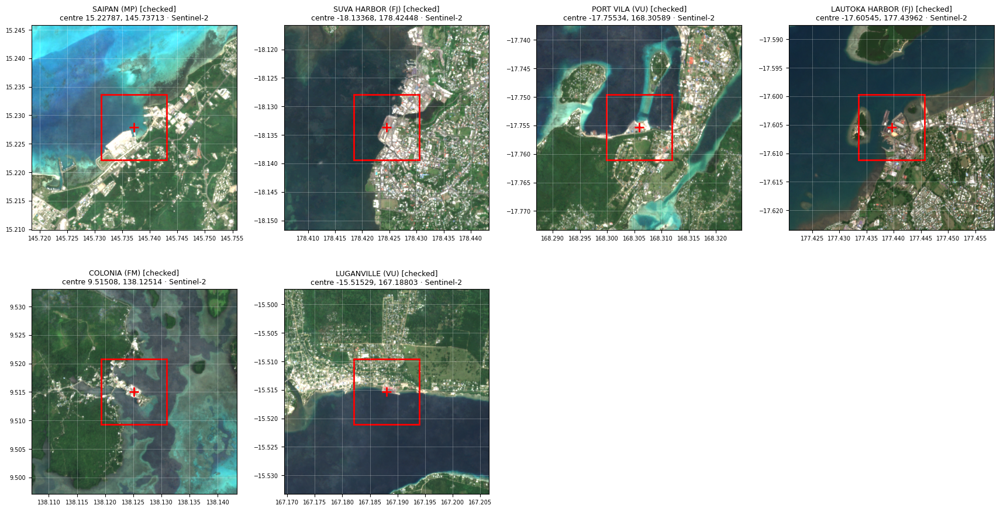

In [11]:
# Port location thumbnails — check each patch sits on the port before downloading
#
# Each thumbnail is a 4 km × 4 km true-colour Sentinel-2 view (cloud-masked
# composite) with the 1.28 km patch outlined in red and its centre marked "+".
# The axes are latitude / longitude, so if the red box is out on the water you
# can read off a better centre point (on the wharf) straight from the axes.
# Add it to COORDINATE_OVERRIDES in the cell above, re-run that cell, then
# re-run this one to confirm the box now covers the port.

import io
from PIL import Image
from matplotlib.patches import Rectangle

THUMB_WIDTH_METRES = 4000          # area shown around each port
THUMB_PIXELS = 400
PATCH_WIDTH_METRES = globals().get("PATCH_SIZE_METRES", 1280)
IMAGERY_START, IMAGERY_END = "2023-01-01", "2025-01-01"


def box_bounds(lat, lon, width_m):
    """West, south, east, north of a square width_m wide centred on lat/lon."""
    half_lat = (width_m / 2) / 111320
    half_lon = (width_m / 2) / (111320 * np.cos(np.radians(lat)))
    return lon - half_lon, lat - half_lat, lon + half_lon, lat + half_lat


def mask_s2_clouds(image):
    qa = image.select("QA60")
    clear = qa.bitwiseAnd(1 << 10).eq(0).And(qa.bitwiseAnd(1 << 11).eq(0))
    return image.updateMask(clear)


def fetch_thumbnail(lat, lon):
    """True-colour Sentinel-2 thumbnail; falls back to Sentinel-1 radar if S2 fails."""
    west, south, east, north = box_bounds(lat, lon, THUMB_WIDTH_METRES)
    region = ee.Geometry.Rectangle([west, south, east, north], "EPSG:4326", False)
    params = {"region": region, "dimensions": THUMB_PIXELS,
              "crs": "EPSG:4326", "format": "png"}

    try:
        s2 = (
            ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
            .filterBounds(region)
            .filterDate(IMAGERY_START, IMAGERY_END)
            .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40))
            .map(mask_s2_clouds)
            .median()
        )
        url = s2.visualize(bands=["B4", "B3", "B2"], min=0, max=2500,
                           gamma=1.3).getThumbURL(params)
        source = "Sentinel-2"
    except Exception:
        s1 = (
            ee.ImageCollection("COPERNICUS/S1_GRD")
            .filterBounds(region)
            .filterDate(IMAGERY_START, IMAGERY_END)
            .filter(ee.Filter.eq("instrumentMode", "IW"))
            .select("VV")
            .median()
        )
        url = s1.visualize(min=-25, max=5).getThumbURL(params)
        source = "Sentinel-1 VV"

    response = requests.get(url, timeout=120)
    response.raise_for_status()
    return Image.open(io.BytesIO(response.content)), (west, east, south, north), source


port_rows = ports.drop_duplicates("port_key").reset_index(drop=True)
n_ports = len(port_rows)
n_cols = 4
n_rows = int(np.ceil(n_ports / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.3 * n_cols, 4.6 * n_rows), squeeze=False)

for ax, row in zip(axes.flat, port_rows.itertuples()):
    lat, lon = float(row.latitude), float(row.longitude)
    title = f"{row.port_name} ({row.country}) [{row.coordinate_status}]"

    try:
        image, extent, source = fetch_thumbnail(lat, lon)
    except Exception as error:
        ax.set_title(f"{title}\nthumbnail failed", fontsize=9)
        ax.text(0.5, 0.5, str(error)[:120], ha="center", va="center",
                wrap=True, fontsize=7, transform=ax.transAxes)
        ax.axis("off")
        continue

    ax.imshow(image, extent=extent)

    # The 1.28 km patch that will actually be downloaded
    w, s, e, n = box_bounds(lat, lon, PATCH_WIDTH_METRES)
    ax.add_patch(Rectangle((w, s), e - w, n - s, fill=False, edgecolor="red", linewidth=2))
    ax.plot(lon, lat, "r+", markersize=12, markeredgewidth=2)

    ax.set_aspect(1 / np.cos(np.radians(lat)))   # square in metres
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.tick_params(labelsize=7)
    ax.grid(color="white", alpha=0.35, linewidth=0.5)
    ax.set_title(f"{title}\ncentre {lat:.5f}, {lon:.5f} · {source}", fontsize=9)

for ax in axes.flat[n_ports:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
PATCH_SIZE_PIXELS = 128
PATCH_SIZE_METRES = 1280

# Start with the requested 50% threshold, but treat it as a parameter to test.
WATER_OCCURRENCE_THRESHOLD = 50
NODATA_VALUE = -9999.0

BAND_NAMES = [
    "pre_VV",
    "pre_VH",
    "post_VV",
    "post_VH",
    "change_VV",
    "change_VH"
]

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Lucy_CNN/Sentinel1_patches"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

surface_water_occurrence = (
    ee.Image("JRC/GSW1_4/GlobalSurfaceWater")
    .select("occurrence")
)


def get_local_utm_crs(latitude, longitude):
    """Return the local WGS84 UTM CRS as an EPSG string."""

    zone = int((float(longitude) + 180) // 6) + 1
    zone = min(max(zone, 1), 60)
    epsg = (32600 if float(latitude) >= 0 else 32700) + zone
    return f"EPSG:{epsg}"


def make_patch_aoi(row):
    """Create a 1,280 m square in the port's local UTM projection."""

    latitude = float(row["latitude"])
    longitude = float(row["longitude"])
    export_crs = get_local_utm_crs(latitude, longitude)
    projection = ee.Projection(export_crs)

    point = ee.Geometry.Point([longitude, latitude])
    point_projected = point.transform(projection, 1)

    aoi = (
        point_projected
        .buffer(PATCH_SIZE_METRES / 2, 1)
        .bounds(1, projection)
    )

    return aoi, export_crs


def get_s1_collection(
    aoi,
    start_date,
    end_date,
    orbit_pass,
    relative_orbit=None
):
    """Obtain homogeneous 10 m Sentinel-1 IW images with VV and VH."""

    collection = (
        ee.ImageCollection("COPERNICUS/S1_GRD")
        .filterBounds(aoi)
        .filterDate(start_date, end_date)
        .filter(ee.Filter.eq("instrumentMode", "IW"))
        .filter(ee.Filter.eq("resolution_meters", 10))
        .filter(
            ee.Filter.listContains(
                "transmitterReceiverPolarisation",
                "VV"
            )
        )
        .filter(
            ee.Filter.listContains(
                "transmitterReceiverPolarisation",
                "VH"
            )
        )
        .filter(ee.Filter.eq("orbitProperties_pass", orbit_pass))
    )

    if relative_orbit is not None:
        collection = collection.filter(
            ee.Filter.eq(
                "relativeOrbitNumber_start",
                int(relative_orbit)
            )
        )

    return collection.select(["VV", "VH"])


def choose_orbit(aoi, pre_start, pre_end, post_start, post_end):
    """Select one pass and one relative orbit represented in both periods."""

    candidates = []

    for orbit_pass in ["ASCENDING", "DESCENDING"]:
        pre_collection = get_s1_collection(
            aoi, pre_start, pre_end, orbit_pass
        )
        post_collection = get_s1_collection(
            aoi, post_start, post_end, orbit_pass
        )

        pre_histogram = (
            pre_collection
            .aggregate_histogram("relativeOrbitNumber_start")
            .getInfo()
        )
        post_histogram = (
            post_collection
            .aggregate_histogram("relativeOrbitNumber_start")
            .getInfo()
        )

        common_orbits = set(pre_histogram) & set(post_histogram)

        for relative_orbit_key in common_orbits:
            pre_count = int(pre_histogram[relative_orbit_key])
            post_count = int(post_histogram[relative_orbit_key])

            candidates.append({
                "orbit": orbit_pass,
                "relative_orbit": int(float(relative_orbit_key)),
                "pre_count": pre_count,
                "post_count": post_count,
                "usable_count": min(pre_count, post_count),
                "total_count": pre_count + post_count
            })

    if not candidates:
        return None

    return max(
        candidates,
        key=lambda item: (
            item["usable_count"],
            item["total_count"]
        )
    )


def create_land_mask():
    """Return a fully valid binary mask: 1 land, 0 frequent water."""

    # Start from an unmasked constant. `where` changes it only where the
    # JRC band is valid and meets the threshold. This avoids propagating
    # the occurrence band's unusual fractional mask into the SAR bands.
    water_mask = (
        ee.Image.constant(0)
        .where(
            surface_water_occurrence.gte(
                WATER_OCCURRENCE_THRESHOLD
            ),
            1
        )
        .rename("frequent_water")
        .toByte()
    )

    return water_mask.Not().rename("land_mask")


land_mask = create_land_mask()


def create_six_band_patch(row):
    """Create masked pre, post and dB-change bands for one patch."""

    aoi, export_crs = make_patch_aoi(row)

    orbit_info = choose_orbit(
        aoi,
        row["pre_start"],
        row["pre_end"],
        row["post_start"],
        row["post_end"]
    )

    if orbit_info is None:
        return None, None, None

    orbit_pass = orbit_info["orbit"]
    relative_orbit = orbit_info["relative_orbit"]

    pre = (
        get_s1_collection(
            aoi,
            row["pre_start"],
            row["pre_end"],
            orbit_pass,
            relative_orbit
        )
        .median()
        .select(["VV", "VH"])
    )

    post = (
        get_s1_collection(
            aoi,
            row["post_start"],
            row["post_end"],
            orbit_pass,
            relative_orbit
        )
        .median()
        .select(["VV", "VH"])
    )

    # COPERNICUS/S1_GRD is in dB, so subtraction is a dB log-ratio.
    change = post.subtract(pre).rename([
        "change_VV",
        "change_VH"
    ])

    six_band_image = (
        pre.rename(["pre_VV", "pre_VH"])
        .addBands(post.rename(["post_VV", "post_VH"]))
        .addBands(change)
        .toFloat()
        .updateMask(land_mask)
        .unmask(NODATA_VALUE)
        .clip(aoi)
    )

    orbit_info = {
        **orbit_info,
        "export_crs": export_crs,
        "water_occurrence_threshold": WATER_OCCURRENCE_THRESHOLD,
        "nodata_value": NODATA_VALUE
    }

    return six_band_image, aoi, orbit_info


print("Functions and permanent-water mask created.")

Functions and permanent-water mask created.


In [13]:
import requests
import shutil
from pathlib import Path

# Save locally in Colab first
LOCAL_OUTPUT_DIR = Path("/content/Sentinel1_patches")
LOCAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Google Drive backup location
DRIVE_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Lucy_CNN/Sentinel1_patches"
)
DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

metadata_records = []

for _, row in ports.iterrows():
    print(f"Processing: {row['port_name']}")

    image, aoi, orbit_info = create_six_band_patch(row)

    if image is None:
        print("Skipped: no common relative orbit in both periods.")
        continue

    filename = f"{row['sample_id']}.tif"
    local_path = LOCAL_OUTPUT_DIR / filename
    drive_path = DRIVE_OUTPUT_DIR / filename

    download_url = image.getDownloadURL({
        "name": row["sample_id"],
        "region": aoi,
        "dimensions": [PATCH_SIZE_PIXELS, PATCH_SIZE_PIXELS],
        "crs": orbit_info["export_crs"],
        "format": "GEO_TIFF",
        "filePerBand": False
    })

    response = requests.get(download_url, timeout=300)
    response.raise_for_status()

    with open(local_path, "wb") as file:
        file.write(response.content)

    # Record NoData and band names in the GeoTIFF itself.
    with rasterio.open(local_path, "r+") as dataset:
        dataset.nodata = NODATA_VALUE
        for band_number, band_name in enumerate(BAND_NAMES, start=1):
            dataset.set_band_description(band_number, band_name)

    with rasterio.open(local_path) as dataset:
        if dataset.count != 6:
            raise ValueError(f"Expected 6 bands, found {dataset.count}")
        if (dataset.height, dataset.width) != (
            PATCH_SIZE_PIXELS,
            PATCH_SIZE_PIXELS
        ):
            raise ValueError(
                "Unexpected raster dimensions: "
                f"{dataset.height} x {dataset.width}"
            )

    shutil.copy2(local_path, drive_path)

    metadata_records.append({
        **row.to_dict(),
        "orbit_pass": orbit_info["orbit"],
        "relative_orbit": orbit_info["relative_orbit"],
        "number_pre_images": orbit_info["pre_count"],
        "number_post_images": orbit_info["post_count"],
        "water_occurrence_threshold": orbit_info[
            "water_occurrence_threshold"
        ],
        "nodata_value": orbit_info["nodata_value"],
        "export_crs": orbit_info["export_crs"],
        "image_file": filename
    })

    print("Saved locally:", local_path)
    print("Saved to Drive:", drive_path)

metadata = pd.DataFrame(metadata_records)

local_metadata_path = LOCAL_OUTPUT_DIR / "metadata.csv"
drive_metadata_path = DRIVE_OUTPUT_DIR / "metadata.csv"

metadata.to_csv(local_metadata_path, index=False)
metadata.to_csv(drive_metadata_path, index=False)

print("\nFiles in local folder:")
print(list(LOCAL_OUTPUT_DIR.glob("*")))

metadata

Processing: SAIPAN
Skipped: no common relative orbit in both periods.
Processing: SUVA HARBOR


Saved locally: /content/Sentinel1_patches/suva_harbor_fj_ana_2021.tif
Saved to Drive: /content/drive/MyDrive/Lucy_CNN/Sentinel1_patches/suva_harbor_fj_ana_2021.tif
Processing: PORT VILA
Skipped: no common relative orbit in both periods.
Processing: LAUTOKA HARBOR
Skipped: no common relative orbit in both periods.
Processing: COLONIA
Skipped: no common relative orbit in both periods.
Processing: LUGANVILLE


Saved locally: /content/Sentinel1_patches/luganville_vu_harold_2020.tif
Saved to Drive: /content/drive/MyDrive/Lucy_CNN/Sentinel1_patches/luganville_vu_harold_2020.tif
Processing: COLONIA
Skipped: no common relative orbit in both periods.
Processing: LAUTOKA HARBOR
Skipped: no common relative orbit in both periods.
Processing: LUGANVILLE
Skipped: no common relative orbit in both periods.
Processing: PORT VILA
Skipped: no common relative orbit in both periods.
Processing: SAIPAN


Saved locally: /content/Sentinel1_patches/saipan_mp_ctrl_20170815.tif
Saved to Drive: /content/drive/MyDrive/Lucy_CNN/Sentinel1_patches/saipan_mp_ctrl_20170815.tif
Processing: SUVA HARBOR


Saved locally: /content/Sentinel1_patches/suva_harbor_fj_ctrl_20200131.tif
Saved to Drive: /content/drive/MyDrive/Lucy_CNN/Sentinel1_patches/suva_harbor_fj_ctrl_20200131.tif

Files in local folder:
[PosixPath('/content/Sentinel1_patches/suva_harbor_fj_ctrl_20200131.tif'), PosixPath('/content/Sentinel1_patches/metadata.csv'), PosixPath('/content/Sentinel1_patches/suva_harbor_fj_ana_2021.tif'), PosixPath('/content/Sentinel1_patches/luganville_vu_harold_2020.tif'), PosixPath('/content/Sentinel1_patches/saipan_mp_ctrl_20170815.tif')]


,sample_id,sample_type,port_key,port_name,country,world_port_index,latitude,longitude,coordinate_status,disaster,...,post_end,label,orbit_pass,relative_orbit,number_pre_images,number_post_images,water_occurrence_threshold,nodata_value,export_crs,image_file
0,suva_harbor_fj_ana_2021,event,suva_harbor_fj,SUVA HARBOR,FJ,55540,-18.133677,178.424478,checked,Tropical Cyclone Ana (2021),...,2021-02-11,-1,ASCENDING,139,1,1,50,-9999.0,EPSG:32760,suva_harbor_fj_ana_2021.tif
1,luganville_vu_harold_2020,event,luganville_vu,LUGANVILLE,VU,57200,-15.515290,167.188030,checked,Tropical Cyclone Harold (2020),...,2020-04-17,-1,DESCENDING,59,1,1,50,-9999.0,EPSG:32758,luganville_vu_harold_2020.tif
2,saipan_mp_ctrl_20170815,control_temporal,saipan_mp,SAIPAN,MP,56520,15.227872,145.737131,checked,No cyclone (temporal control),...,2017-08-26,-1,DESCENDING,31,1,1,50,-9999.0,EPSG:32655,saipan_mp_ctrl_20170815.tif
3,suva_harbor_fj_ctrl_20200131,control_temporal,suva_harbor_fj,SUVA HARBOR,FJ,55540,-18.133677,178.424478,checked,No cyclone (temporal control),...,2020-02-11,-1,ASCENDING,66,1,1,50,-9999.0,EPSG:32760,suva_harbor_fj_ctrl_20200131.tif


Current GeoTIFF files found: 4

Filename: suva_harbor_fj_ana_2021.tif
Shape: (6, 128, 128)
Number of bands: 6
Coordinate system: EPSG:32760
Pixel size: (10.018123652048416, 9.958355283553828)
NoData value: -9999.0
Valid land fraction: 0.498


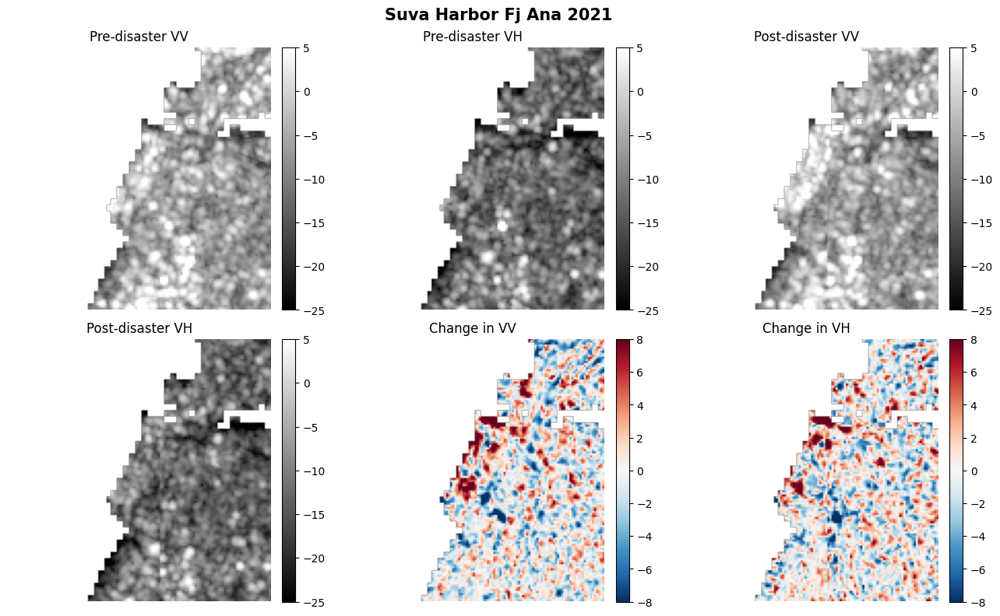


Filename: luganville_vu_harold_2020.tif
Shape: (6, 128, 128)
Number of bands: 6
Coordinate system: EPSG:32758
Pixel size: (10.021580017307315, 9.959849404898705)
NoData value: -9999.0
Valid land fraction: 0.494


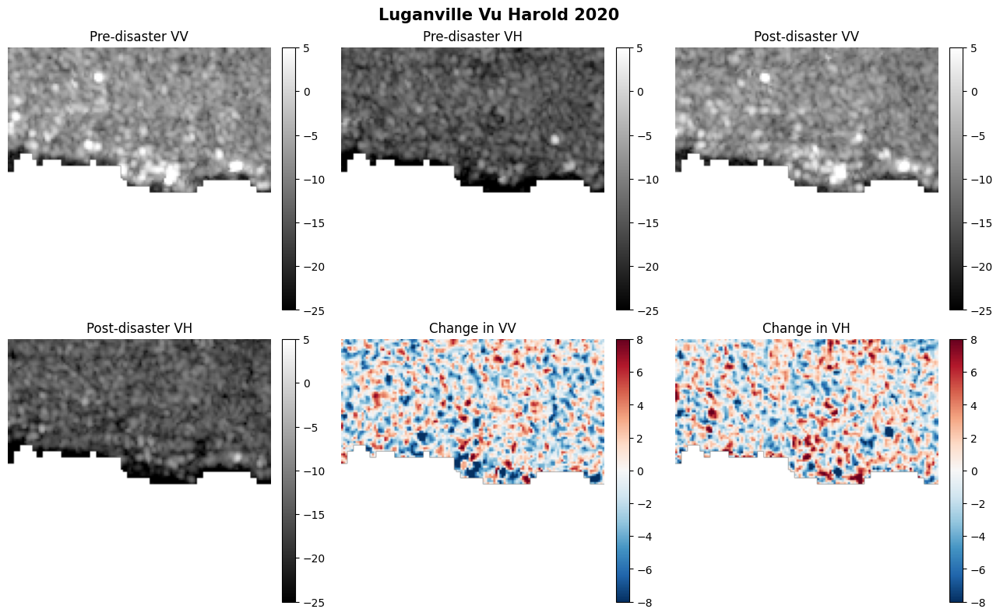


Filename: saipan_mp_ctrl_20170815.tif
Shape: (6, 128, 128)
Number of bands: 6
Coordinate system: EPSG:32655
Pixel size: (10.016381404996082, 9.954963248777858)
NoData value: -9999.0
Valid land fraction: 0.509


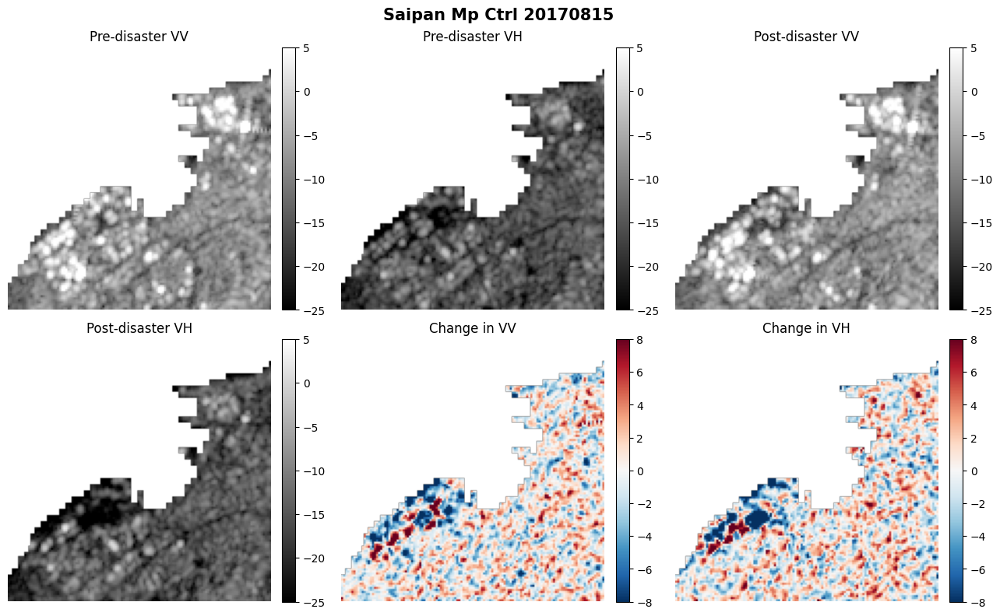


Filename: suva_harbor_fj_ctrl_20200131.tif
Shape: (6, 128, 128)
Number of bands: 6
Coordinate system: EPSG:32760
Pixel size: (10.018123652048416, 9.958355283553828)
NoData value: -9999.0
Valid land fraction: 0.498


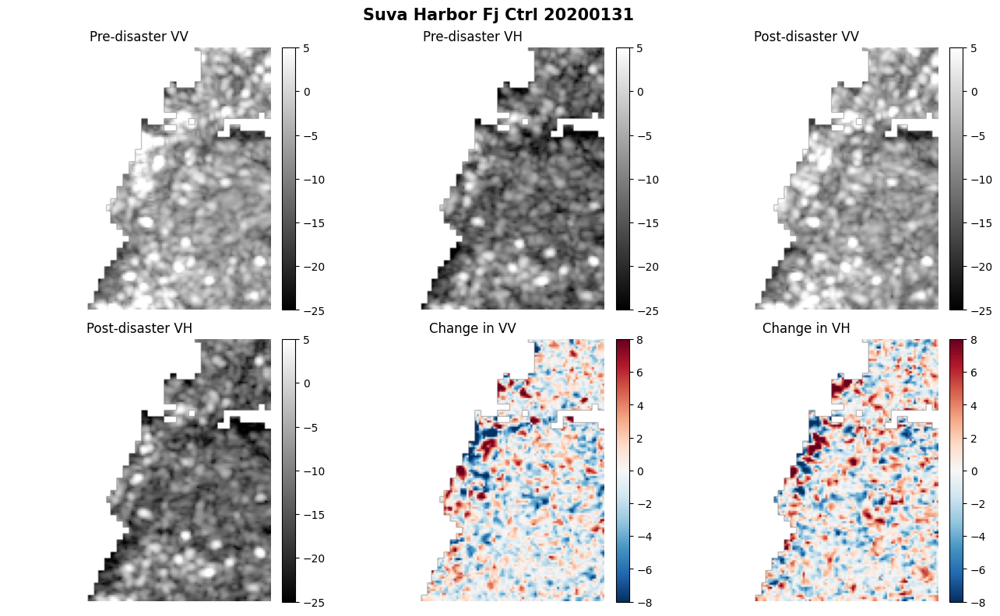

In [14]:
# Display the five current Sentinel-1 port patches

titles = [
    "Pre-disaster VV",
    "Pre-disaster VH",
    "Post-disaster VV",
    "Post-disaster VH",
    "Change in VV",
    "Change in VH"
]

current_files = [
    LOCAL_OUTPUT_DIR / f"{sample_id}.tif"
    for sample_id in ports["sample_id"]
]

existing_files = [
    path for path in current_files
    if path.exists()
]

print("Current GeoTIFF files found:", len(existing_files))

if len(existing_files) == 0:
    print("No current GeoTIFF files were found.")

else:
    for example_path in existing_files:
        with rasterio.open(example_path) as src:
            patch = src.read().astype(np.float32)
            nodata_value = src.nodata

            print()
            print("Filename:", example_path.name)
            print("Shape:", patch.shape)
            print("Number of bands:", src.count)
            print("Coordinate system:", src.crs)
            print("Pixel size:", src.res)
            print("NoData value:", nodata_value)

        if nodata_value is not None:
            patch[patch == nodata_value] = np.nan
        else:
            patch[patch == NODATA_VALUE] = np.nan

        valid_land_fraction = np.isfinite(patch[0]).mean()
        print("Valid land fraction:", round(valid_land_fraction, 3))

        fig, axes = plt.subplots(2, 3, figsize=(13, 8))

        for band_number, ax in enumerate(axes.flat):
            if band_number < 4:
                plot = ax.imshow(
                    patch[band_number],
                    cmap="gray",
                    vmin=-25,
                    vmax=5
                )
            else:
                plot = ax.imshow(
                    patch[band_number],
                    cmap="RdBu_r",
                    vmin=-8,
                    vmax=8
                )

            ax.set_title(titles[band_number])
            ax.axis("off")
            plt.colorbar(plot, ax=ax, fraction=0.046, pad=0.04)

        port_title = example_path.stem.replace("_", " ").title()
        plt.suptitle(port_title, fontsize=15, fontweight="bold")
        plt.tight_layout()
        plt.show()

In [15]:
# Create and download a 3 × 3 patch grid around each port

import requests
import shutil
import numpy as np
import pandas as pd
from pathlib import Path

# Each patch is 1,280 m wide.
# A 640 m step produces 50% overlap between neighbouring patches.
GRID_STEP_METRES = 640

GRID_OFFSETS = [
    -GRID_STEP_METRES,
    0,
    GRID_STEP_METRES
]

GRID_LOCAL_DIR = Path(
    "/content/Sentinel1_grid_patches"
)

GRID_DRIVE_DIR = Path(
    "/content/drive/MyDrive/"
    "Lucy_CNN/Sentinel1_grid_patches"
)

GRID_LOCAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

GRID_DRIVE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def offset_coordinates(
    latitude,
    longitude,
    north_offset_metres,
    east_offset_metres
):
    """
    Move a latitude/longitude coordinate by approximate
    north and east distances in metres.
    """

    metres_per_degree_latitude = 111320

    metres_per_degree_longitude = (
        111320
        * np.cos(np.radians(latitude))
    )

    new_latitude = (
        latitude
        + north_offset_metres
        / metres_per_degree_latitude
    )

    new_longitude = (
        longitude
        + east_offset_metres
        / metres_per_degree_longitude
    )

    return new_latitude, new_longitude


# Create the 45 candidate grid locations

grid_rows = []

for _, port in ports.iterrows():

    for row_number, north_offset in enumerate(
        GRID_OFFSETS,
        start=1
    ):

        for column_number, east_offset in enumerate(
            GRID_OFFSETS,
            start=1
        ):

            patch_latitude, patch_longitude = (
                offset_coordinates(
                    float(port["latitude"]),
                    float(port["longitude"]),
                    north_offset,
                    east_offset
                )
            )

            grid_rows.append({
                "sample_id": (
                    f"{port['sample_id']}"
                    f"_r{row_number}_c{column_number}"
                ),
                "source_port_id": port["sample_id"],
                "port_key": port.get("port_key", ""),
                "sample_type": port.get("sample_type", "event"),
                "port_name": port["port_name"],
                "country": port["country"],
                "world_port_index": port["world_port_index"],
                "latitude": patch_latitude,
                "longitude": patch_longitude,
                "north_offset_m": north_offset,
                "east_offset_m": east_offset,
                "disaster": port["disaster"],
                "storm_sid": port.get("storm_sid", ""),
                "storm_name": port.get("storm_name", ""),
                "distance_km": port.get("distance_km", np.nan),
                "wind_kt_at_cpa": port.get("wind_kt_at_cpa", np.nan),
                "exposure_class": port.get("exposure_class", ""),
                "control_for": port.get("control_for", ""),
                "pre_start": port["pre_start"],
                "pre_end": port["pre_end"],
                "post_start": port["post_start"],
                "post_end": port["post_end"],

                # No supervised damage label is used by the CNN.
                "label": -1
            })

grid_patches = pd.DataFrame(grid_rows)

print(
    "Candidate grid patches:",
    len(grid_patches)
)


# Download each six-band patch

download_records = []

for patch_number, (_, patch_row) in enumerate(
    grid_patches.iterrows(),
    start=1
):

    print(
        f"[{patch_number}/{len(grid_patches)}]",
        patch_row["sample_id"]
    )

    image, aoi, orbit_info = create_six_band_patch(
        patch_row
    )

    if image is None:
        print("  Skipped: no matching imagery.")
        continue

    filename = f"{patch_row['sample_id']}.tif"

    local_path = GRID_LOCAL_DIR / filename
    drive_path = GRID_DRIVE_DIR / filename

    try:
        download_url = image.getDownloadURL({
            "name": patch_row["sample_id"],
            "region": aoi,
            "dimensions": [
                PATCH_SIZE_PIXELS,
                PATCH_SIZE_PIXELS
            ],
            "crs": orbit_info["export_crs"],
            "format": "GEO_TIFF",
            "filePerBand": False
        })

        response = requests.get(
            download_url,
            timeout=300
        )

        response.raise_for_status()

        with open(local_path, "wb") as file:
            file.write(response.content)

        with rasterio.open(local_path, "r+") as dataset:
            dataset.nodata = NODATA_VALUE
            for band_number, band_name in enumerate(BAND_NAMES, start=1):
                dataset.set_band_description(band_number, band_name)

        shutil.copy2(
            local_path,
            drive_path
        )

        record = patch_row.to_dict()

        record.update({
            "orbit_pass": orbit_info["orbit"],
            "relative_orbit": orbit_info["relative_orbit"],
            "water_occurrence_threshold": WATER_OCCURRENCE_THRESHOLD,
            "nodata_value": NODATA_VALUE,
            "export_crs": orbit_info["export_crs"],
            "number_pre_images": orbit_info["pre_count"],
            "number_post_images": orbit_info["post_count"],
            "image_file": filename,
            "download_status": "success"
        })

        download_records.append(record)

        print("  Saved:", filename)

    except Exception as error:

        print("  Download failed:", error)


# Save grid metadata

grid_metadata = pd.DataFrame(download_records)

local_metadata_path = (
    GRID_LOCAL_DIR / "grid_metadata.csv"
)

drive_metadata_path = (
    GRID_DRIVE_DIR / "grid_metadata.csv"
)

grid_metadata.to_csv(
    local_metadata_path,
    index=False
)

grid_metadata.to_csv(
    drive_metadata_path,
    index=False
)

print()
print(
    "Successful grid patches:",
    len(grid_metadata)
)

print(
    "Saved to:",
    GRID_DRIVE_DIR
)

display(grid_metadata.head())

Candidate grid patches: 108
[1/108] saipan_mp_soudelor_goni_2015_r1_c1
  Skipped: no matching imagery.
[2/108] saipan_mp_soudelor_goni_2015_r1_c2
  Skipped: no matching imagery.
[3/108] saipan_mp_soudelor_goni_2015_r1_c3
  Skipped: no matching imagery.
[4/108] saipan_mp_soudelor_goni_2015_r2_c1
  Skipped: no matching imagery.
[5/108] saipan_mp_soudelor_goni_2015_r2_c2
  Skipped: no matching imagery.
[6/108] saipan_mp_soudelor_goni_2015_r2_c3
  Skipped: no matching imagery.
[7/108] saipan_mp_soudelor_goni_2015_r3_c1
  Skipped: no matching imagery.
[8/108] saipan_mp_soudelor_goni_2015_r3_c2
  Skipped: no matching imagery.
[9/108] saipan_mp_soudelor_goni_2015_r3_c3
  Skipped: no matching imagery.
[10/108] suva_harbor_fj_ana_2021_r1_c1


  Saved: suva_harbor_fj_ana_2021_r1_c1.tif
[11/108] suva_harbor_fj_ana_2021_r1_c2


  Saved: suva_harbor_fj_ana_2021_r1_c2.tif
[12/108] suva_harbor_fj_ana_2021_r1_c3


  Saved: suva_harbor_fj_ana_2021_r1_c3.tif
[13/108] suva_harbor_fj_ana_2021_r2_c1


  Saved: suva_harbor_fj_ana_2021_r2_c1.tif
[14/108] suva_harbor_fj_ana_2021_r2_c2


...

  Saved: suva_harbor_fj_ctrl_20200131_r2_c3.tif
[106/108] suva_harbor_fj_ctrl_20200131_r3_c1


  Saved: suva_harbor_fj_ctrl_20200131_r3_c1.tif
[107/108] suva_harbor_fj_ctrl_20200131_r3_c2


  Saved: suva_harbor_fj_ctrl_20200131_r3_c2.tif
[108/108] suva_harbor_fj_ctrl_20200131_r3_c3


  Saved: suva_harbor_fj_ctrl_20200131_r3_c3.tif

Successful grid patches: 36
Saved to: /content/drive/MyDrive/Lucy_CNN/Sentinel1_grid_patches


,sample_id,source_port_id,port_key,sample_type,port_name,country,world_port_index,latitude,longitude,north_offset_m,...,label,orbit_pass,relative_orbit,water_occurrence_threshold,nodata_value,export_crs,number_pre_images,number_post_images,image_file,download_status
0,suva_harbor_fj_ana_2021_r1_c1,suva_harbor_fj_ana_2021,suva_harbor_fj,event,SUVA HARBOR,FJ,55540,-18.139426,178.418428,-640,...,-1,ASCENDING,139,50,-9999.0,EPSG:32760,1,1,suva_harbor_fj_ana_2021_r1_c1.tif,success
1,suva_harbor_fj_ana_2021_r1_c2,suva_harbor_fj_ana_2021,suva_harbor_fj,event,SUVA HARBOR,FJ,55540,-18.139426,178.424478,-640,...,-1,ASCENDING,139,50,-9999.0,EPSG:32760,1,1,suva_harbor_fj_ana_2021_r1_c2.tif,success
2,suva_harbor_fj_ana_2021_r1_c3,suva_harbor_fj_ana_2021,suva_harbor_fj,event,SUVA HARBOR,FJ,55540,-18.139426,178.430528,-640,...,-1,ASCENDING,139,50,-9999.0,EPSG:32760,1,1,suva_harbor_fj_ana_2021_r1_c3.tif,success
3,suva_harbor_fj_ana_2021_r2_c1,suva_harbor_fj_ana_2021,suva_harbor_fj,event,SUVA HARBOR,FJ,55540,-18.133677,178.418428,0,...,-1,ASCENDING,139,50,-9999.0,EPSG:32760,1,1,suva_harbor_fj_ana_2021_r2_c1.tif,success
4,suva_harbor_fj_ana_2021_r2_c2,suva_harbor_fj_ana_2021,suva_harbor_fj,event,SUVA HARBOR,FJ,55540,-18.133677,178.424478,0,...,-1,ASCENDING,139,50,-9999.0,EPSG:32760,1,1,suva_harbor_fj_ana_2021_r2_c2.tif,success


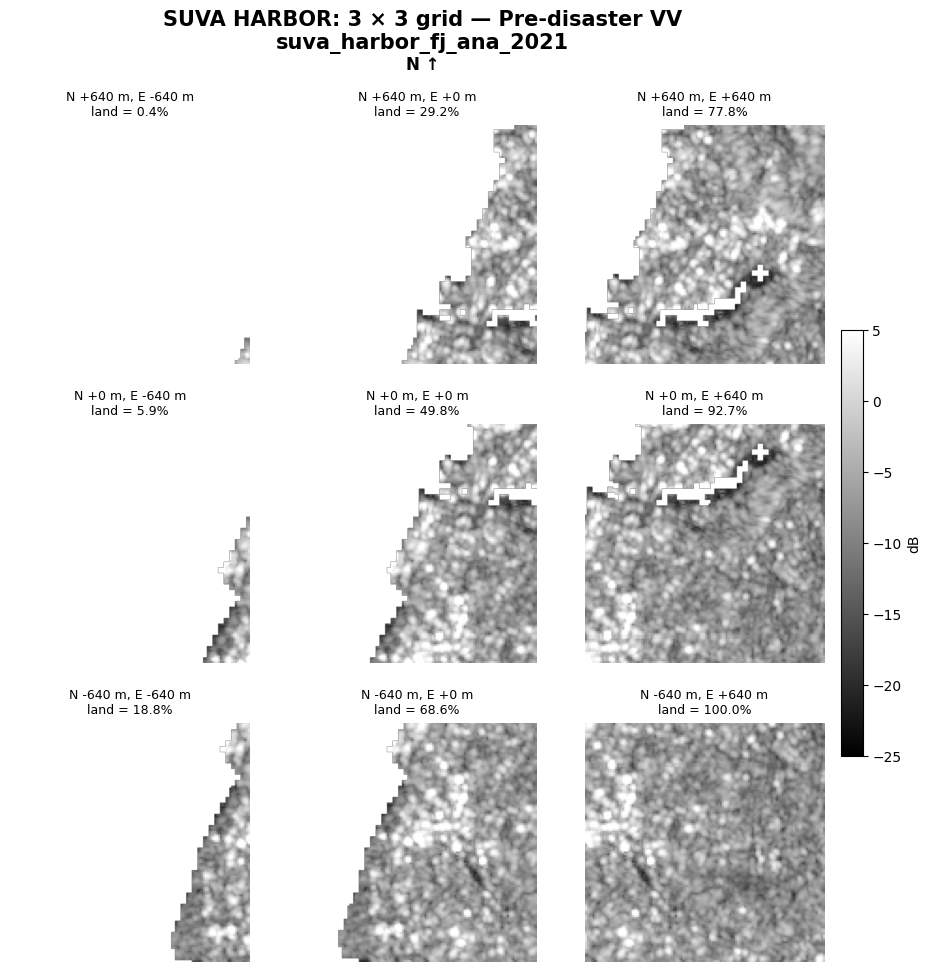

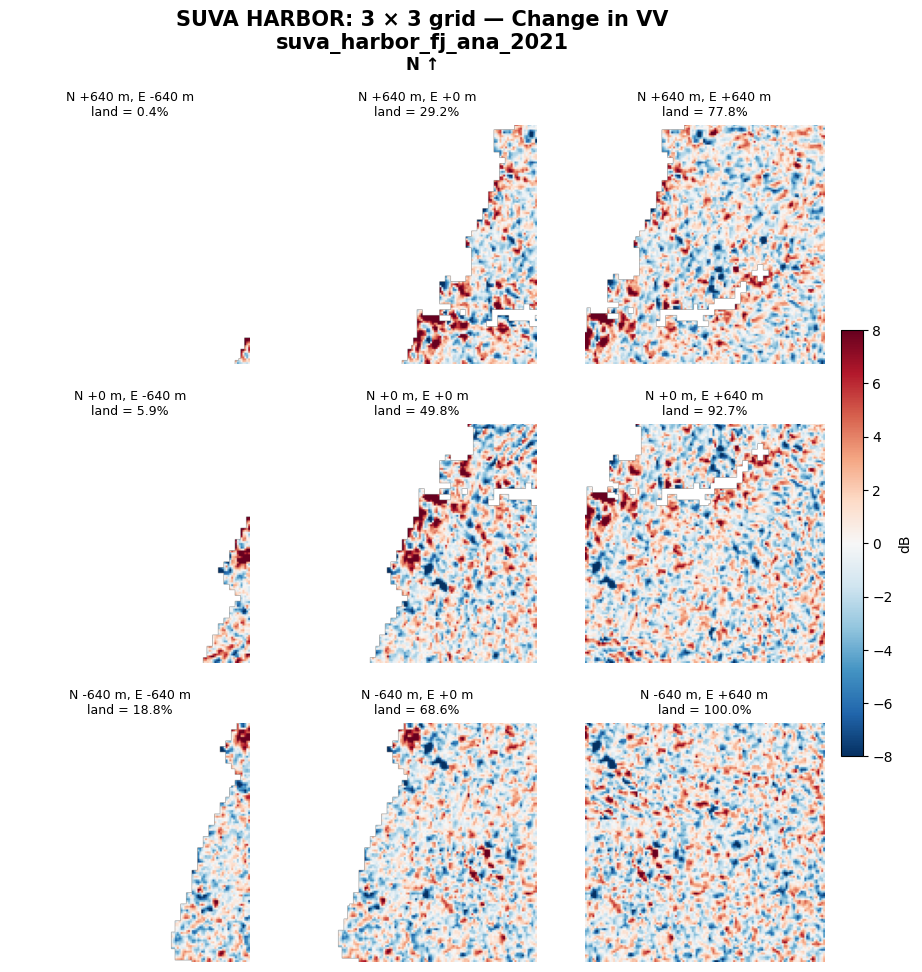

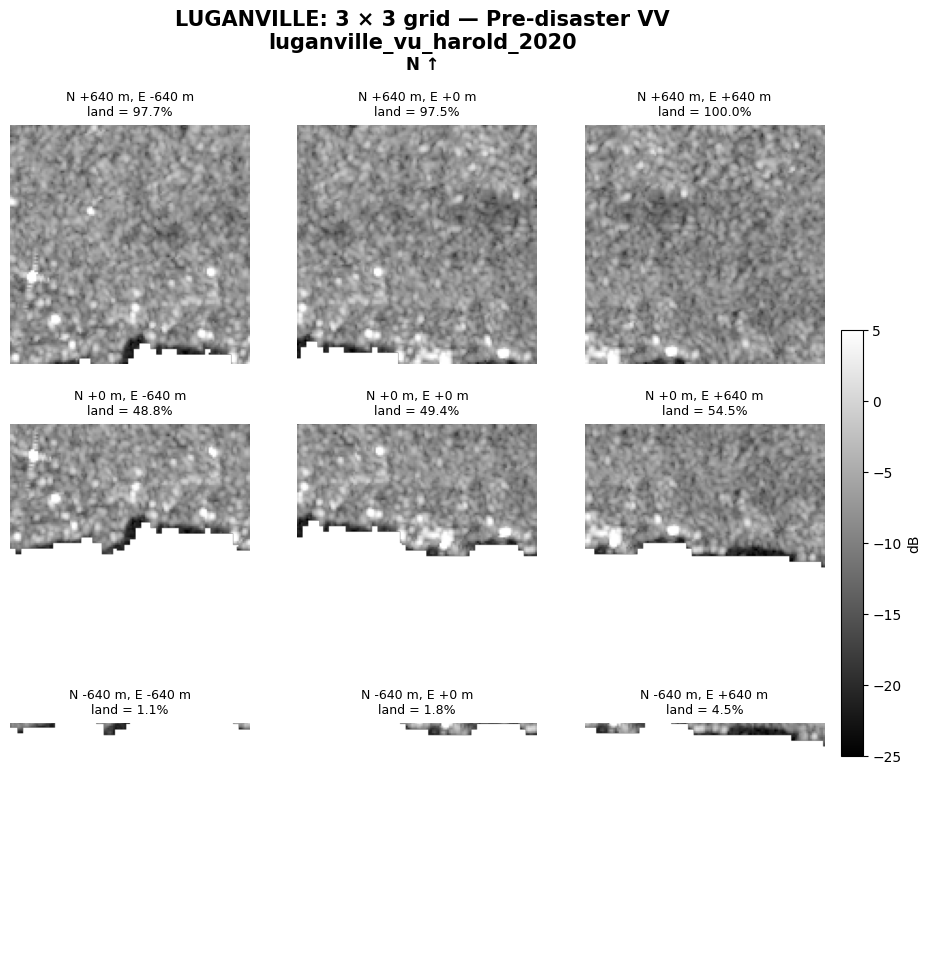

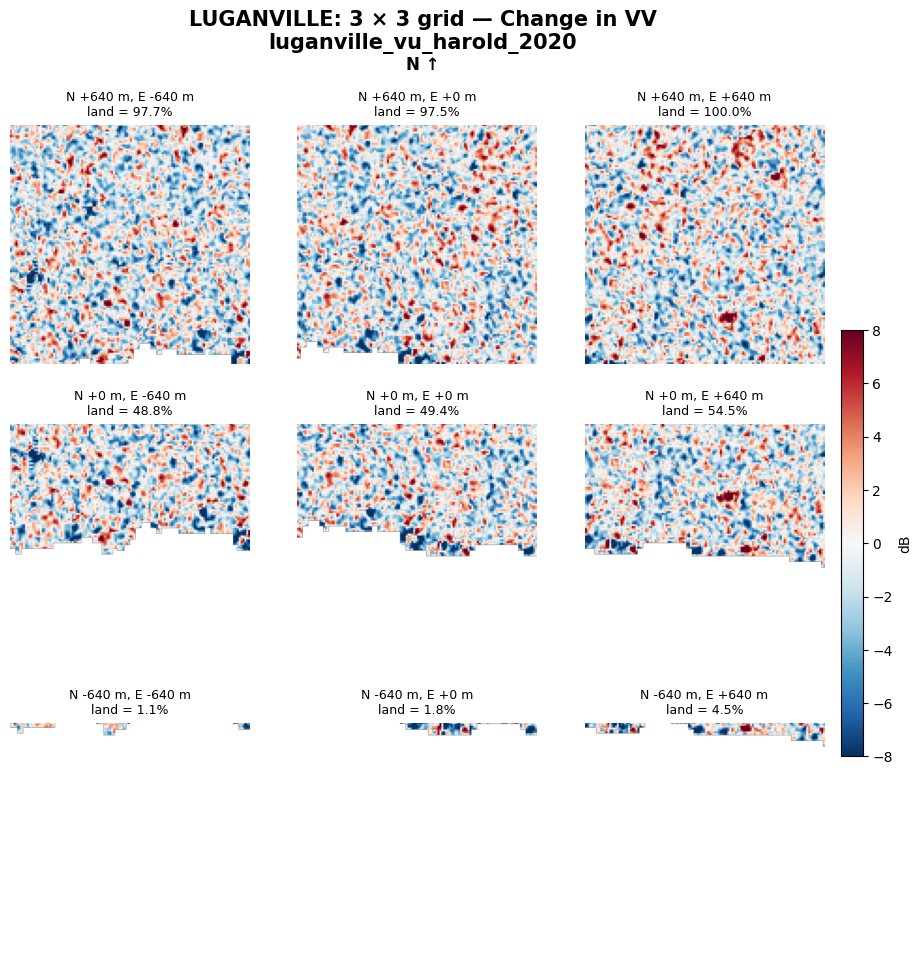

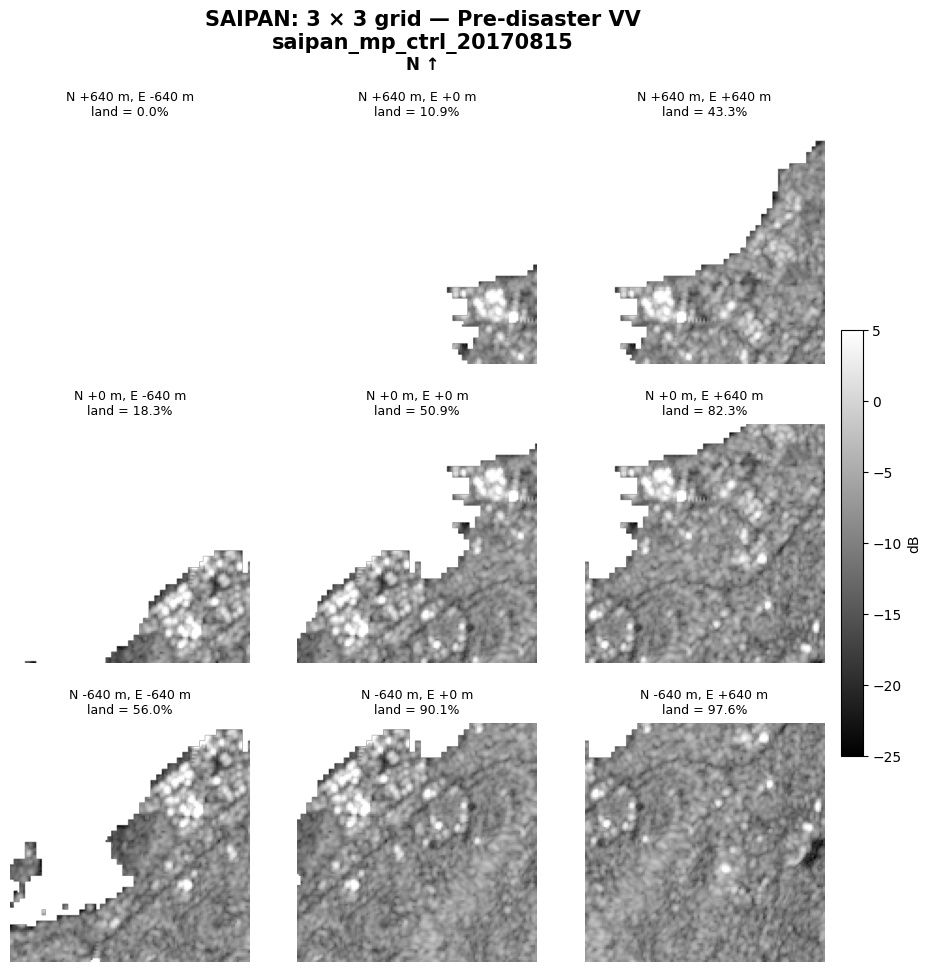

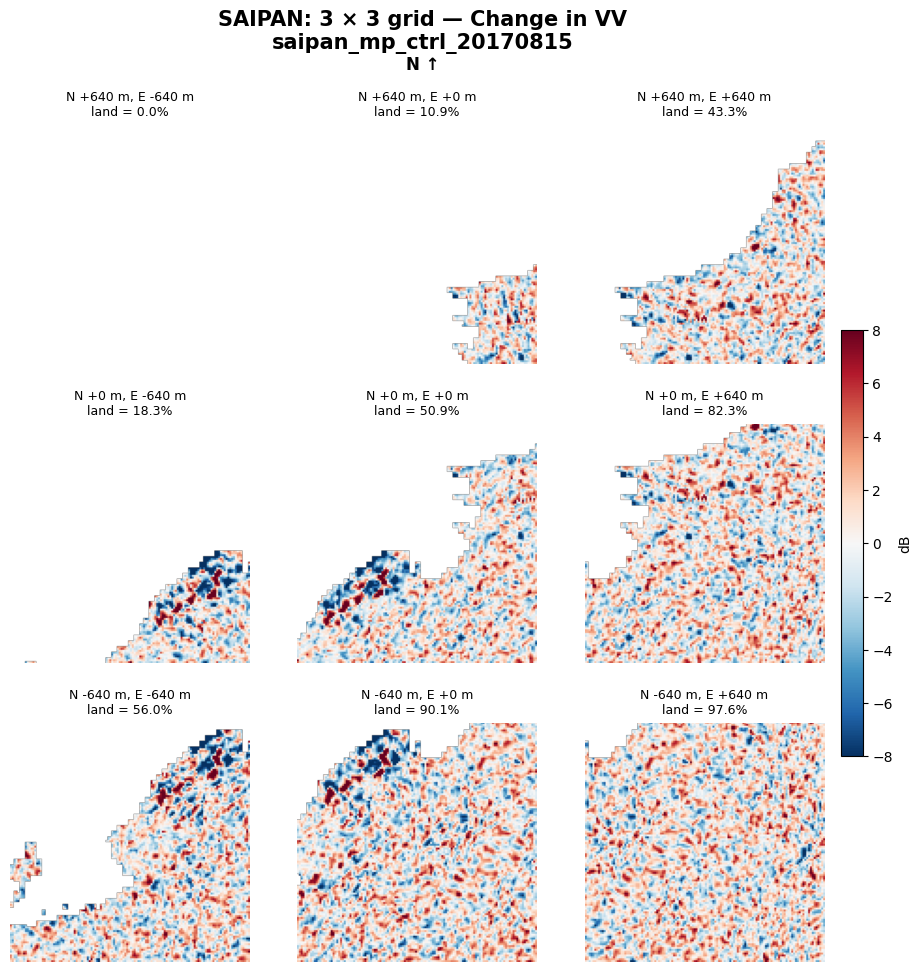

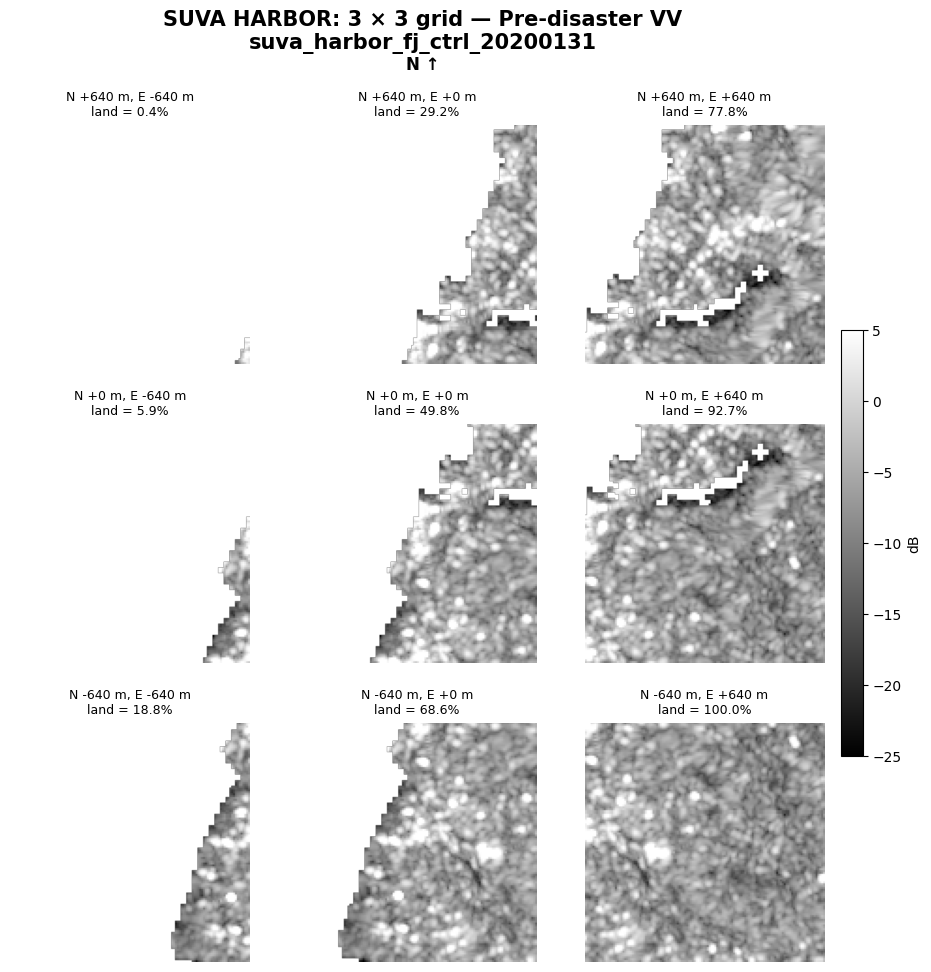

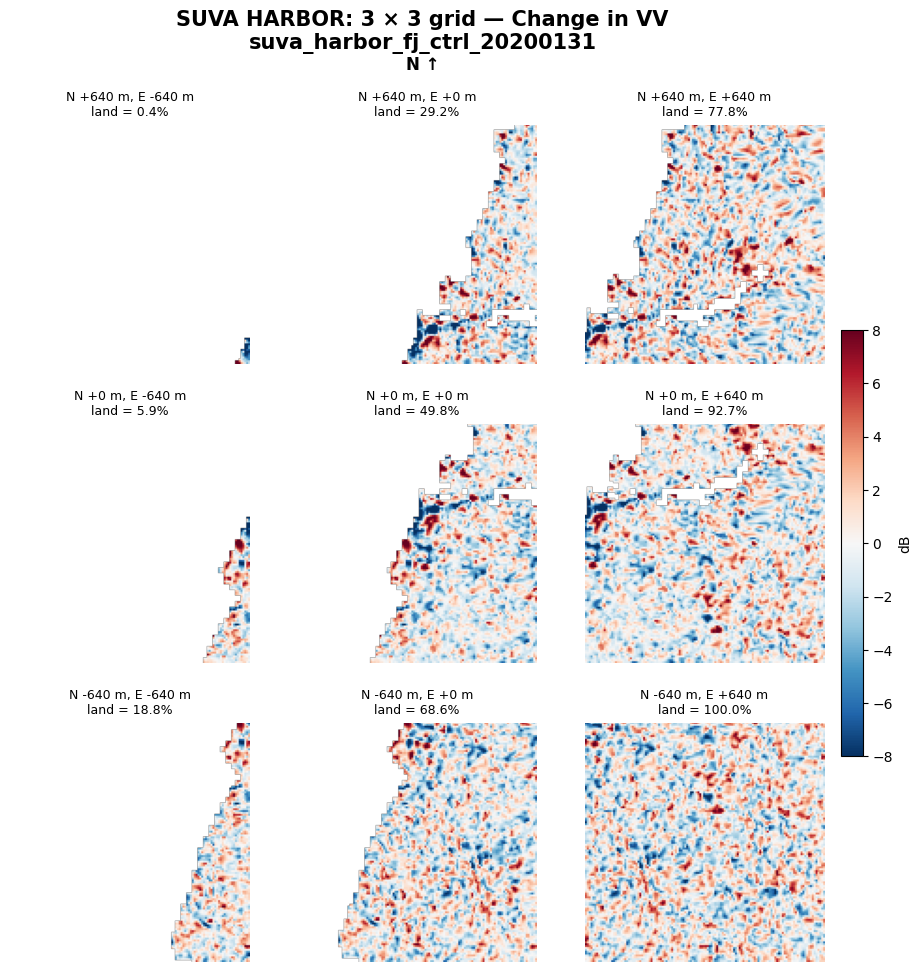

In [16]:
# Display the spatial 3 × 3 patch grid for every port.

DISPLAY_BANDS = {
    0: ("Pre-disaster VV", "gray", -25, 5),
    4: ("Change in VV", "RdBu_r", -8, 8)
}


def read_grid_band(raster_path, band_index):
    """Read one raster band and convert NoData to NaN."""

    with rasterio.open(raster_path) as src:
        image = src.read(band_index + 1).astype(np.float32)
        nodata_value = src.nodata

    if nodata_value is not None:
        image[image == nodata_value] = np.nan
    else:
        image[image == NODATA_VALUE] = np.nan

    return image


def display_port_grid(port_rows, band_index, band_settings):
    """Display nine overlapping patches in their geographic positions."""

    band_title, colour_map, minimum, maximum = band_settings

    port_name = port_rows.iloc[0]["port_name"]
    source_port_id = port_rows.iloc[0]["source_port_id"]

    # North is at the top and west is on the left.
    north_offsets = sorted(
        port_rows["north_offset_m"].unique(),
        reverse=True
    )

    east_offsets = sorted(
        port_rows["east_offset_m"].unique()
    )

    fig, axes = plt.subplots(
        3,
        3,
        figsize=(11, 11)
    )

    for plot_row, north_offset in enumerate(north_offsets):

        for plot_column, east_offset in enumerate(east_offsets):

            ax = axes[plot_row, plot_column]

            matching_row = port_rows[
                (port_rows["north_offset_m"] == north_offset)
                &
                (port_rows["east_offset_m"] == east_offset)
            ]

            if matching_row.empty:
                ax.text(
                    0.5,
                    0.5,
                    "Missing metadata",
                    ha="center",
                    va="center"
                )
                ax.axis("off")
                continue

            patch_row = matching_row.iloc[0]
            filename = patch_row["image_file"]

            local_path = GRID_LOCAL_DIR / filename
            drive_path = GRID_DRIVE_DIR / filename

            raster_path = (
                local_path
                if local_path.exists()
                else drive_path
            )

            if not raster_path.exists():
                ax.text(
                    0.5,
                    0.5,
                    "File missing",
                    ha="center",
                    va="center"
                )
                ax.axis("off")
                continue

            image = read_grid_band(
                raster_path,
                band_index
            )

            valid_land_fraction = float(
                np.isfinite(image).mean()
            )

            plot = ax.imshow(
                image,
                cmap=colour_map,
                vmin=minimum,
                vmax=maximum
            )

            ax.set_title(
                f"N {north_offset:+.0f} m, "
                f"E {east_offset:+.0f} m\n"
                f"land = {valid_land_fraction:.1%}",
                fontsize=9
            )

            ax.axis("off")

    fig.suptitle(
        f"{port_name}: 3 × 3 grid — {band_title}\n"
        f"{source_port_id}",
        fontsize=15,
        fontweight="bold"
    )

    # One shared colour bar for the complete grid.
    fig.colorbar(
        plot,
        ax=axes,
        fraction=0.025,
        pad=0.02,
        label="dB"
    )

    # Add a north indicator.
    fig.text(
        0.5,
        0.925,
        "N ↑",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

    plt.show()


# Produce two figures for each port:
# 1. Pre-disaster VV for locating land and infrastructure.
# 2. VV change for inspecting radar changes.

for source_port_id, port_rows in grid_metadata.groupby(
    "source_port_id",
    sort=False
):

    for band_index, band_settings in DISPLAY_BANDS.items():

        display_port_grid(
            port_rows.reset_index(drop=True),
            band_index,
            band_settings
        )

In [17]:
# Export the metadata needed by the unsupervised CNN stage.

UNSUPERVISED_DIR = Path(
    "/content/drive/MyDrive/Lucy_CNN/unsupervised_cnn"
)
UNSUPERVISED_DIR.mkdir(parents=True, exist_ok=True)

UNSUPERVISED_MANIFEST_PATH = (
    UNSUPERVISED_DIR / "unsupervised_manifest.csv"
)

UNSUPERVISED_CONFIG_PATH = (
    UNSUPERVISED_DIR / "preprocessing_config.json"
)

manifest_columns = [
    "sample_id",
    "source_port_id",
    "port_key",
    "sample_type",
    "port_name",
    "country",
    "world_port_index",
    "latitude",
    "longitude",
    "north_offset_m",
    "east_offset_m",
    "disaster",
    "storm_sid",
    "storm_name",
    "distance_km",
    "wind_kt_at_cpa",
    "exposure_class",
    "control_for",
    "pre_start",
    "pre_end",
    "post_start",
    "post_end",
    "orbit_pass",
    "relative_orbit",
    "water_occurrence_threshold",
    "nodata_value",
    "export_crs",
    "number_pre_images",
    "number_post_images",
    "image_file",
]

missing_manifest_columns = [
    column
    for column in manifest_columns
    if column not in grid_metadata.columns
]

if missing_manifest_columns:
    raise ValueError(
        "Missing manifest columns: "
        f"{missing_manifest_columns}"
    )

unsupervised_manifest = (
    grid_metadata[manifest_columns]
    .copy()
    .sort_values(
        [
            "source_port_id",
            "north_offset_m",
            "east_offset_m",
        ]
    )
    .reset_index(drop=True)
)

unsupervised_manifest.to_csv(
    UNSUPERVISED_MANIFEST_PATH,
    index=False,
)

preprocessing_config = {
    "patch_size_pixels": int(PATCH_SIZE_PIXELS),
    "patch_size_metres": int(PATCH_SIZE_METRES),
    "grid_step_metres": int(GRID_STEP_METRES),
    "band_names": list(BAND_NAMES),
    "nodata_value": float(NODATA_VALUE),
    "water_occurrence_threshold": float(
        WATER_OCCURRENCE_THRESHOLD
    ),
    "patch_directory": str(GRID_DRIVE_DIR),
}

import json

with open(
    UNSUPERVISED_CONFIG_PATH,
    "w",
) as file:
    json.dump(
        preprocessing_config,
        file,
        indent=2,
    )

print(
    "Manifest:",
    UNSUPERVISED_MANIFEST_PATH,
)

print(
    "Configuration:",
    UNSUPERVISED_CONFIG_PATH,
)

print(
    "Patches exported:",
    len(unsupervised_manifest),
)

display(
    unsupervised_manifest.head()
)


Manifest: /content/drive/MyDrive/Lucy_CNN/unsupervised_cnn/unsupervised_manifest.csv
Configuration: /content/drive/MyDrive/Lucy_CNN/unsupervised_cnn/preprocessing_config.json
Patches exported: 36


,sample_id,source_port_id,port_key,sample_type,port_name,country,world_port_index,latitude,longitude,north_offset_m,...,post_start,post_end,orbit_pass,relative_orbit,water_occurrence_threshold,nodata_value,export_crs,number_pre_images,number_post_images,image_file
0,luganville_vu_harold_2020_r1_c1,luganville_vu_harold_2020,luganville_vu,event,LUGANVILLE,VU,57200,-15.521039,167.182063,-640,...,2020-04-07,2020-04-17,DESCENDING,59,50,-9999.0,EPSG:32758,1,1,luganville_vu_harold_2020_r1_c1.tif
1,luganville_vu_harold_2020_r1_c2,luganville_vu_harold_2020,luganville_vu,event,LUGANVILLE,VU,57200,-15.521039,167.188030,-640,...,2020-04-07,2020-04-17,DESCENDING,59,50,-9999.0,EPSG:32758,1,1,luganville_vu_harold_2020_r1_c2.tif
2,luganville_vu_harold_2020_r1_c3,luganville_vu_harold_2020,luganville_vu,event,LUGANVILLE,VU,57200,-15.521039,167.193997,-640,...,2020-04-07,2020-04-17,DESCENDING,59,50,-9999.0,EPSG:32758,1,1,luganville_vu_harold_2020_r1_c3.tif
3,luganville_vu_harold_2020_r2_c1,luganville_vu_harold_2020,luganville_vu,event,LUGANVILLE,VU,57200,-15.515290,167.182063,0,...,2020-04-07,2020-04-17,DESCENDING,59,50,-9999.0,EPSG:32758,1,1,luganville_vu_harold_2020_r2_c1.tif
4,luganville_vu_harold_2020_r2_c2,luganville_vu_harold_2020,luganville_vu,event,LUGANVILLE,VU,57200,-15.515290,167.188030,0,...,2020-04-07,2020-04-17,DESCENDING,59,50,-9999.0,EPSG:32758,1,1,luganville_vu_harold_2020_r2_c2.tif
